# **Loan Default Prediction**

### Capstone Project - Practical Data Science (Classification) | Milestone Submission

**Learner:** Shubham Garg
**Program:** MIT Professional Education - Applied AI and Data Science Program
**Dataset:** Home Equity (HMEQ) - 5,960 recent home equity loans

## **Problem Definition**

### **The Context:**

A large share of a retail bank's profit comes from the interest it earns on home loans and home equity lines of credit. The single biggest threat to that profit is the borrower who does not pay back: every loan that turns into a non-performing asset (NPA) wipes out the interest earned on many good loans. The bank therefore has to be judicious about whom it approves.

Today the approval decision is made through a manual study of the application by an underwriter. That process is slow, expensive, inconsistent from one underwriter to another, and vulnerable to human error and bias. Earlier attempts to automate the process used hand-written heuristics. With the data the bank now has on past loans and their outcomes, it is possible to **learn** the approval decision from evidence instead of opinion, while making sure the new model does not simply replicate the biases of the old manual process.

**Some facts that size the problem.** In the bank's own recent book of 5,960 home equity loans, **1,189 (19.9%) ended in default or serious delinquency**, all of them approved by the current process. Those defaulted loans averaged about \$16,900 each, so roughly \$20 million of principal was put at risk, and if the bank recovers about half through the collateral, roughly \$10 million was lost on this book alone. Every ten defaulters avoided saves, at that rate, about \$85,000; every good customer wrongly turned away costs only the interest margin on one loan, a few thousand dollars at most.

**Advantages of solving it.** A reliable, explainable scoring model (1) cuts credit losses by stopping likely defaulters at the door, (2) protects revenue by not declining good customers unnecessarily, (3) speeds up and standardises decisions so underwriters spend their time on the genuinely uncertain cases, and (4) gives the bank documented, consistent reasons for every decision, which is both a regulatory requirement and a fairness safeguard.

### **The objective:**

Build a classification model that predicts, at the time of application, whether a client is likely to default on a home equity loan, and use that model to give the bank clear recommendations on which applicant attributes matter most when approving a loan.

The project has several goals, in priority order:

1. **Catch defaulters early** - maximise the share of future defaulters identified at application time (recall on the default class), because a missed defaulter is the costliest error.
2. **Protect good business** - keep the share of wrongly declined good customers acceptable (precision), so that risk reduction does not come at the price of lost revenue.
3. **Stay interpretable** - under the Equal Credit Opportunity Act (ECOA) the bank must be able to give an applicant a specific, defensible reason for an adverse decision. A black box that cannot explain a rejection is not usable in production.
4. **Guide policy** - identify the applicant attributes that matter most, so the bank can tighten its approval rules and data collection even before a model is deployed.

### **The key questions:**

1. What share of past applicants defaulted, and how imbalanced is the problem?
2. Which applicant attributes (credit history, debt burden, loan size, job, loan purpose, property value) separate defaulters from repayers?
3. How should missing information be treated? Is the *absence* of information itself a risk signal?
4. Which modelling technique (linear vs. tree-based vs. ensemble) gives the best trade-off between catching defaulters and wrongly rejecting good customers?
5. What is the right measure of success for this business problem, and how do the models compare on it?
6. Which model should the bank adopt, with what settings, and what rules can the bank communicate to applicants and regulators?

### **The problem formulation**:

This is a **supervised binary classification** problem. Each row is a past home equity loan with 12 attributes known at application time and a target `BAD` (1 = defaulted or seriously delinquent, 0 = repaid). We will:

- explore and clean the data (missing values, outliers, encoding);
- train a linear model (Logistic Regression) and non-linear models (Decision Tree, Random Forest);
- tune the non-linear models with cross-validated grid search;
- compare all models on a metric chosen from the business cost of each type of error (**Recall on the defaulter class** as primary, with Precision and F1 as guard-rails so that the bank does not reject too many good customers);
- propose a final solution design and the business rules that follow from it.

## **Data Description:**
The Home Equity dataset (HMEQ) contains baseline and loan performance information for 5,960 recent home equity loans. The target (BAD) is a binary variable that indicates whether an applicant has ultimately defaulted or has been severely delinquent. This adverse outcome occurred in 1,189 cases (20 percent). 12 input variables were registered for each applicant.


* **BAD:** 1 = Client defaulted on loan, 0 = loan repaid

* **LOAN:** Amount of loan approved.

* **MORTDUE:** Amount due on the existing mortgage.

* **VALUE:** Current value of the property.

* **REASON:** Reason for the loan request. (HomeImp = home improvement, DebtCon= debt consolidation which means taking out a new loan to pay off other liabilities and consumer debts)

* **JOB:** The type of job that loan applicant has such as manager, self, etc.

* **YOJ:** Years at present job.

* **DEROG:** Number of major derogatory reports (which indicates a serious delinquency or late payments).

* **DELINQ:** Number of delinquent credit lines (a line of credit becomes delinquent when a borrower does not make the minimum required payments 30 to 60 days past the day on which the payments were due).

* **CLAGE:** Age of the oldest credit line in months.

* **NINQ:** Number of recent credit inquiries.

* **CLNO:** Number of existing credit lines.

* **DEBTINC:** Debt-to-income ratio (all your monthly debt payments divided by your gross monthly income. This number is one way lenders measure your ability to manage the monthly payments to repay the money you plan to borrow.

## **Import the necessary libraries and Data**

In [1]:
# Core libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Pre-processing and model selection
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.inspection import permutation_importance
from scipy import stats
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn import metrics
from sklearn.metrics import (classification_report, confusion_matrix, recall_score,
                             precision_score, f1_score, accuracy_score, roc_auc_score,
                             roc_curve, precision_recall_curve)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 1

In [2]:
# Load the dataset
hm = pd.read_csv("../data/hmeq.csv")

# Work on a copy so the raw data stays untouched
data = hm.copy()

## **Data Overview**

- Reading the dataset
- Understanding the shape of the dataset
- Checking the data types
- Checking for missing values
- Checking for duplicated values

In [3]:
# First five rows
data.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,"25,860.000","39,025.000",HomeImp,Other,10.500,0.000,0.000,94.367,1.000,9.000,NaN
1,1,1300,"70,053.000","68,400.000",HomeImp,Other,7.000,0.000,2.000,121.833,0.000,14.000,NaN
2,1,1500,"13,500.000","16,700.000",HomeImp,Other,4.000,0.000,0.000,149.467,1.000,10.000,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,"97,800.000","112,000.000",HomeImp,Office,3.000,0.000,0.000,93.333,0.000,14.000,NaN


In [4]:
# Last five rows
data.tail()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
5955,0,88900,"57,264.000","90,185.000",DebtCon,Other,16.000,0.000,0.000,221.809,0.000,16.000,36.112
5956,0,89000,"54,576.000","92,937.000",DebtCon,Other,16.000,0.000,0.000,208.692,0.000,15.000,35.860
5957,0,89200,"54,045.000","92,924.000",DebtCon,Other,15.000,0.000,0.000,212.280,0.000,15.000,35.557
5958,0,89800,"50,370.000","91,861.000",DebtCon,Other,14.000,0.000,0.000,213.893,0.000,16.000,34.341
5959,0,89900,"48,811.000","88,934.000",DebtCon,Other,15.000,0.000,0.000,219.601,0.000,16.000,34.572


In [5]:
print(f"The dataset has {data.shape[0]:,} rows and {data.shape[1]} columns.")

The dataset has 5,960 rows and 13 columns.


In [6]:
# Data types and non-null counts
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BAD      5960 non-null   int64  
 1   LOAN     5960 non-null   int64  
 2   MORTDUE  5442 non-null   float64
 3   VALUE    5848 non-null   float64
 4   REASON   5708 non-null   str    
 5   JOB      5681 non-null   str    
 6   YOJ      5445 non-null   float64
 7   DEROG    5252 non-null   float64
 8   DELINQ   5380 non-null   float64
 9   CLAGE    5652 non-null   float64
 10  NINQ     5450 non-null   float64
 11  CLNO     5738 non-null   float64
 12  DEBTINC  4693 non-null   float64
dtypes: float64(9), int64(2), str(2)
memory usage: 605.4 KB


**Observations:**

- There are **5,960 loans and 13 columns**: the target `BAD` plus 12 input attributes.
- `BAD` and `LOAN` are integers with no gaps. `REASON` and `JOB` are text (categorical). All other inputs are numeric floats.
- `DEROG`, `DELINQ`, `NINQ` and `CLNO` are stored as floats but are really **counts** (whole numbers). They can be analysed both as numbers and as ordered categories.
- Every input column except `LOAN` has fewer than 5,960 non-null values, so **missing values are widespread** and must be handled before modelling.

In [7]:
# Count and percentage of missing values in each column
missing = pd.DataFrame({
    "missing_count": data.isnull().sum(),
    "missing_pct": (data.isnull().mean() * 100).round(2)
}).sort_values("missing_pct", ascending=False)
missing

,missing_count,missing_pct
DEBTINC,1267,21.260
DEROG,708,11.880
DELINQ,580,9.730
MORTDUE,518,8.690
YOJ,515,8.640
NINQ,510,8.560
CLAGE,308,5.170
JOB,279,4.680
REASON,252,4.230
CLNO,222,3.720


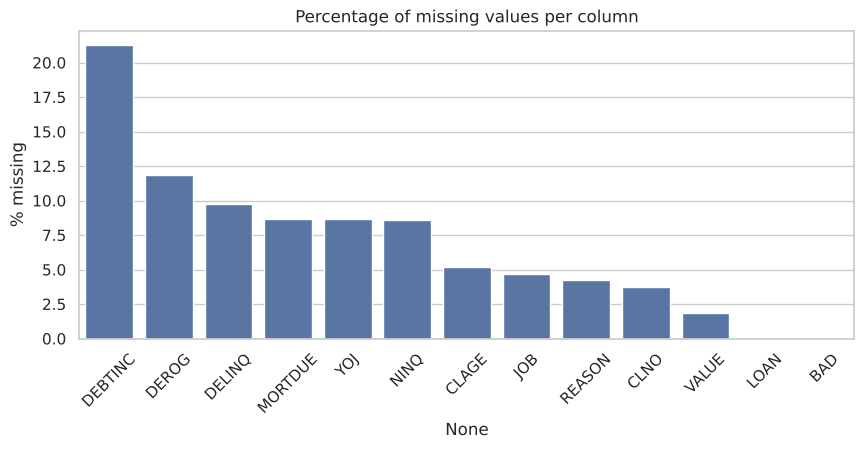

In [8]:
plt.figure(figsize=(10, 4))
sns.barplot(x=missing.index, y=missing["missing_pct"], color="#4C72B0")
plt.title("Percentage of missing values per column")
plt.ylabel("% missing")
plt.xticks(rotation=45)
plt.show()

**Observations:**

- `DEBTINC` (debt-to-income ratio) is missing in **21.3%** of the applications, by far the highest. This is the most important affordability measure a lender has, so its absence is suspicious in itself and we will test later whether missingness is linked to default.
- `DEROG` (11.9%), `DELINQ` (9.7%), `MORTDUE` (8.7%), `YOJ` (8.6%) and `NINQ` (8.6%) have moderate gaps.
- `JOB`, `REASON`, `CLAGE`, `CLNO` and `VALUE` are missing in fewer than 5.2% of rows.
- No column is missing enough to justify dropping it. Dropping rows is also not an option: dropping any row with at least one gap would discard more than 40% of the data. We will **impute** values and **keep a flag** for every imputed cell.

In [9]:
# Rows with a missing value in at least one column, and rows where every input except LOAN is blank
rows_with_na = data.isnull().any(axis=1).sum()
all_blank = data.drop(columns=["BAD", "LOAN"]).isnull().all(axis=1).sum()
print(f"Rows with at least one missing value : {rows_with_na:,} ({rows_with_na/len(data):.1%})")
print(f"Rows where every input except LOAN is blank : {all_blank}")

Rows with at least one missing value : 2,596 (43.6%)
Rows where every input except LOAN is blank : 2


In [10]:
# Duplicate rows
print("Number of duplicated rows:", data.duplicated().sum())

Number of duplicated rows: 0


**Observations:**

- **44% of applications have at least one blank field**, which confirms that row deletion is not viable.
- Two applications have no information at all beyond the loan amount. We keep them: the missing-value flags created later will carry the information that nothing was supplied.
- There are **no duplicate rows**, so no de-duplication is required.

In [11]:
# Convert object columns and the target to the 'category' data type (saves memory, makes intent explicit)
for col in ["REASON", "JOB"]:
    data[col] = data[col].astype("category")
data["BAD"] = data["BAD"].astype("category")
data.dtypes

BAD        category
LOAN          int64
MORTDUE     float64
VALUE       float64
REASON     category
JOB        category
YOJ         float64
DEROG       float64
DELINQ      float64
CLAGE       float64
NINQ        float64
CLNO        float64
DEBTINC     float64
dtype: object

## Summary Statistics

In [12]:
# Summary statistics for the numerical columns
data.describe().T

,count,mean,std,min,25%,50%,75%,max
LOAN,"5,960.000","18,607.970","11,207.480","1,100.000","11,100.000","16,300.000","23,300.000","89,900.000"
MORTDUE,"5,442.000","73,760.817","44,457.609","2,063.000","46,276.000","65,019.000","91,488.000","399,550.000"
VALUE,"5,848.000","101,776.049","57,385.775","8,000.000","66,075.500","89,235.500","119,824.250","855,909.000"
YOJ,"5,445.000",8.922,7.574,0.000,3.000,7.000,13.000,41.000
DEROG,"5,252.000",0.255,0.846,0.000,0.000,0.000,0.000,10.000
DELINQ,"5,380.000",0.449,1.127,0.000,0.000,0.000,0.000,15.000
CLAGE,"5,652.000",179.766,85.810,0.000,115.117,173.467,231.562,"1,168.234"
NINQ,"5,450.000",1.186,1.729,0.000,0.000,1.000,2.000,17.000
CLNO,"5,738.000",21.296,10.139,0.000,15.000,20.000,26.000,71.000
DEBTINC,"4,693.000",33.780,8.602,0.524,29.140,34.818,39.003,203.312


In [13]:
# Summary statistics for the categorical columns (including the target)
data.describe(include="category").T

,count,unique,top,freq
BAD,5960,2,0,4771
REASON,5708,2,DebtCon,3928
JOB,5681,6,Other,2388


In [14]:
# Unique values and their share for each categorical column
for col in ["BAD", "REASON", "JOB"]:
    print(f"Value share in {col}:")
    print((data[col].value_counts(normalize=True) * 100).round(2).to_string())
    print("-" * 40)

Value share in BAD:
BAD
0   80.050
1   19.950
----------------------------------------
Value share in REASON:
REASON
DebtCon   68.820
HomeImp   31.180
----------------------------------------
Value share in JOB:
JOB
Other     42.030
ProfExe   22.460
Office    16.690
Mgr       13.500
Self       3.400
Sales      1.920
----------------------------------------


- **Observations from Summary Statistics**

**Target**
- 19.95% of the loans ended in default (1,189 of 5,960). The classes are **imbalanced roughly 4:1**, so accuracy alone would be misleading (a model that approves everyone is 80% "accurate" and useless).

**Loan and property amounts**
- `LOAN` ranges from \$1,100 to \$89,900 with a median of \$16,300 and mean of \$18,608. The mean is above the median, so the distribution is right-skewed with a tail of large loans.
- `MORTDUE` (median \$65,019) and `VALUE` (median \$89,236) are also right-skewed, and `VALUE` has a maximum of \$855,909, which is an extreme outlier relative to the 75th percentile (\$119,824).

**Employment and credit history**
- `YOJ` (years at present job): median 7 years, maximum 41 years. A quarter of applicants have been in their job 3 years or less.
- `DEROG` and `DELINQ` are zero for at least 75% of applicants (the 75th percentile is 0). Their means (0.25 and 0.45) are driven by a small group with many derogatory reports or delinquent lines - these are the applicants a lender worries about.
- `CLAGE` (age of oldest credit line): median 173 months (about 14.5 years); a maximum of 1,168 months (97 years) is not plausible and is an outlier.
- `NINQ` (recent credit inquiries): median 1, maximum 17.
- `CLNO` (number of credit lines): median 20, maximum 71.

**Debt burden**
- `DEBTINC`: median 34.8%, 75th percentile 39.0%. The maximum of 203% is physically implausible (debt payments twice the income). The 25th-75th range (29% to 39%) is tight, so the few applicants far above 40% stand out.

**Categorical**
- `REASON`: 2 categories; debt consolidation is 68.8% of stated reasons.
- `JOB`: 6 categories; "Other" is the largest (42%), followed by ProfExe (22.5%) and Office (16.7%). Sales (1.9%) and Self-employed (3.4%) are small groups.

## **Exploratory Data Analysis (EDA) and Visualization**

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Leading Questions**:
1. What is the range of values for the loan amount variable "LOAN"?
2. How does the distribution of years at present job "YOJ" vary across the dataset?
3. How many unique categories are there in the REASON variable?
4. What is the most common category in the JOB variable?
5. Is there a relationship between the REASON variable and the proportion of applicants who defaulted on their loan?
6. Do applicants who default have a significantly different loan amount compared to those who repay their loan?
7. Is there a correlation between the value of the property and the loan default rate?
8. Do applicants who default have a significantly different mortgage amount compared to those who repay their loan?

Questions 1 to 4 are answered in the univariate analysis; questions 5 to 8 in the bivariate analysis. A summary of answers is given at the end of the EDA section.

### **Univariate Analysis**

In [15]:
def histogram_boxplot(feature, figsize=(12, 6), bins=None, title=None):
    '''Boxplot on top of a histogram for one numerical feature, with mean (green dashed) and median (black) lines.'''
    f, (ax_box, ax_hist) = plt.subplots(nrows=2, sharex=True,
                                        gridspec_kw={"height_ratios": (0.25, 0.75)},
                                        figsize=figsize)
    sns.boxplot(x=feature, ax=ax_box, showmeans=True, color="violet")
    sns.histplot(x=feature, ax=ax_hist, bins=bins if bins else "auto", color="#4C72B0")
    ax_hist.axvline(np.nanmean(feature), color="green", linestyle="--", label="mean")
    ax_hist.axvline(np.nanmedian(feature), color="black", linestyle="-", label="median")
    ax_hist.legend()
    ax_box.set(xlabel="")
    f.suptitle(title or feature.name, fontsize=13)
    plt.show()

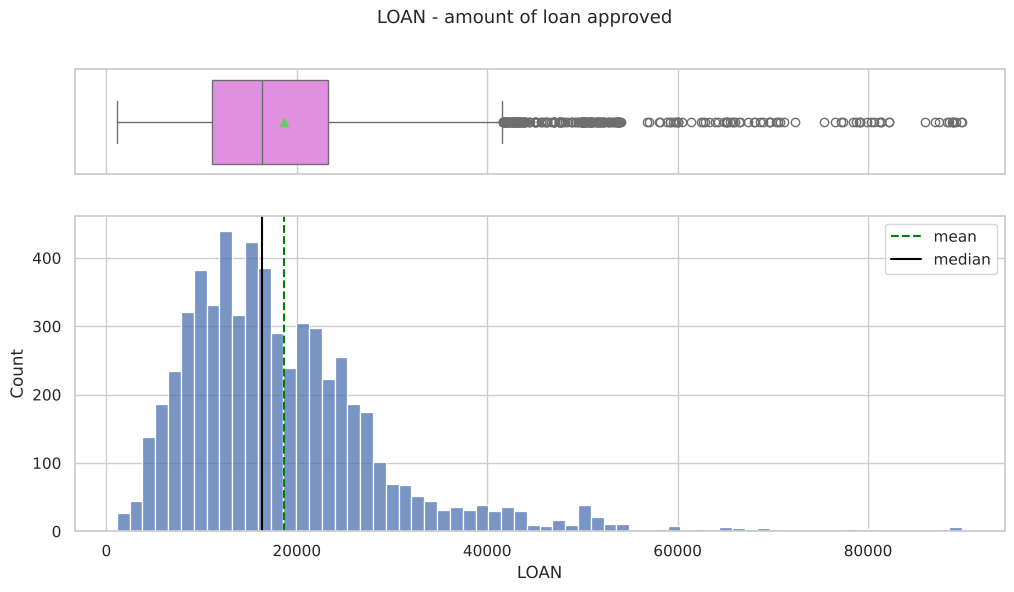

LOAN ranges from $1,100 to $89,900; median $16,300, mean $18,608


In [16]:
histogram_boxplot(data["LOAN"], title="LOAN - amount of loan approved")
print(f"LOAN ranges from ${data['LOAN'].min():,.0f} to ${data['LOAN'].max():,.0f}; "
      f"median ${data['LOAN'].median():,.0f}, mean ${data['LOAN'].mean():,.0f}")

**Insights - LOAN (Q1):**
- Loan amounts range from **\$1,100 to \$89,900**. Half of all loans are below \$16,300 and 75% are below \$23,300.
- The distribution is right-skewed with a long tail; loans above about \$41,000 appear as outliers on the boxplot. Those are genuine large loans, not data errors, so they will be kept for tree models and only capped for the linear model.

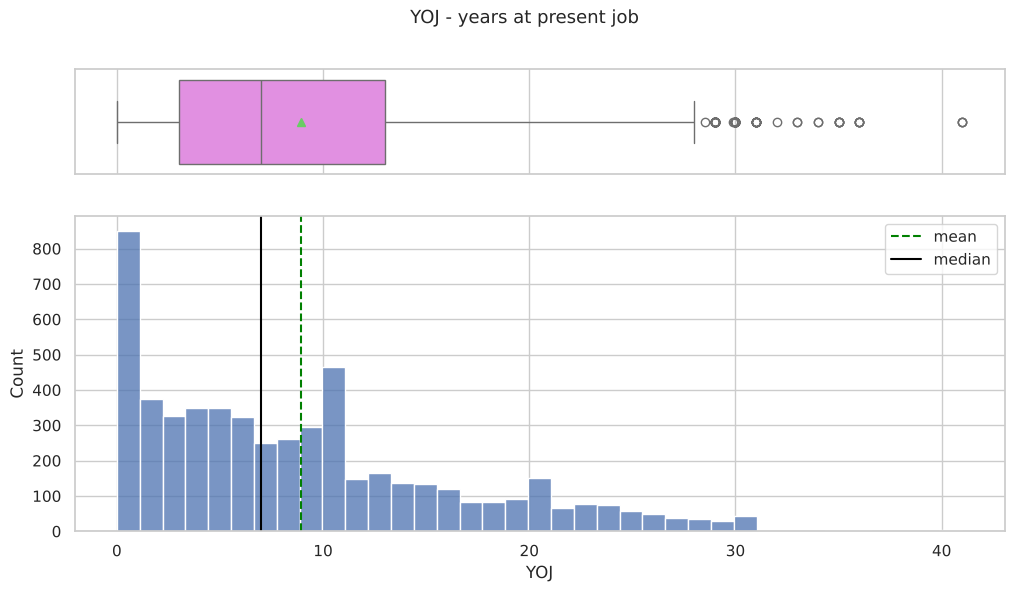

In [17]:
histogram_boxplot(data["YOJ"], title="YOJ - years at present job")

**Insights - YOJ (Q2):**
- Years at the current job is **right-skewed**: the most common values are 0 to 5 years, the median is 7 years and the mean about 9 years.
- There is a long tail of long-tenured applicants (25 to 41 years) flagged as outliers. These are plausible and are kept.
- Job tenure is a mild stability signal; we will check in the bivariate section whether short tenure is linked to default.

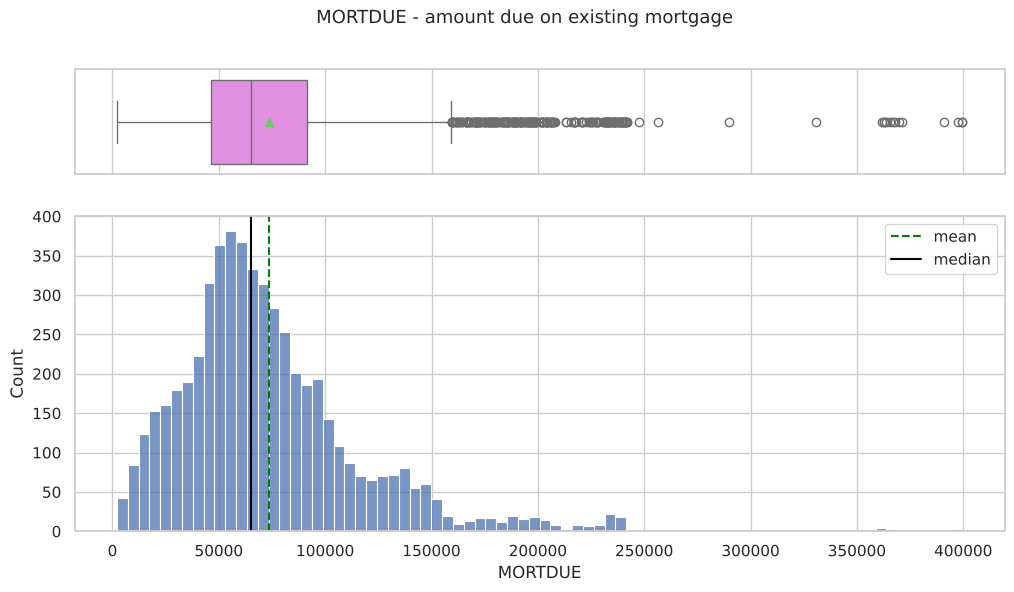

In [18]:
histogram_boxplot(data["MORTDUE"], title="MORTDUE - amount due on existing mortgage")

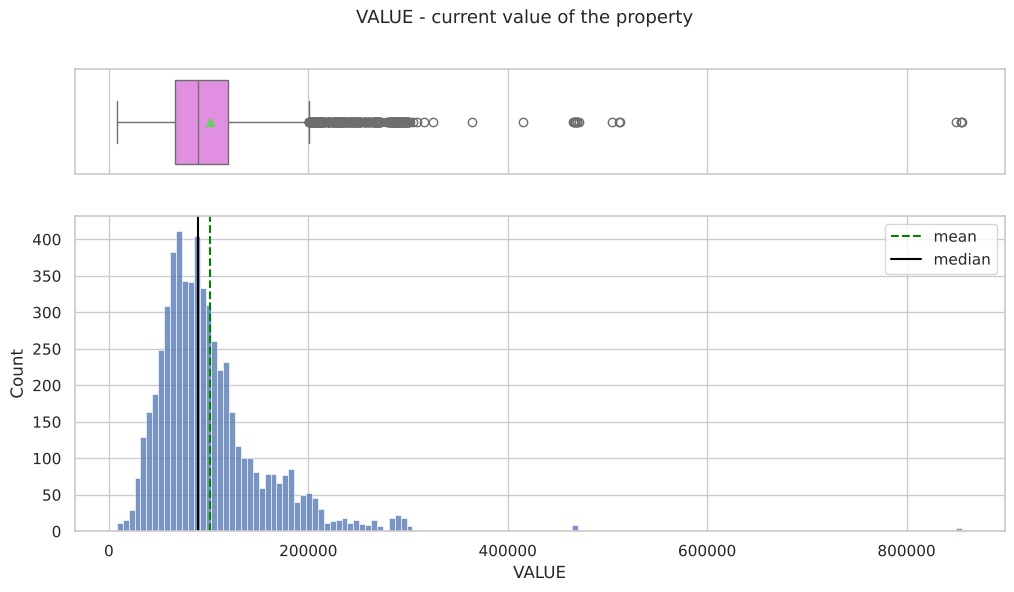

In [19]:
histogram_boxplot(data["VALUE"], title="VALUE - current value of the property")

**Insights - MORTDUE and VALUE:**
- Both are right-skewed with a bulk of properties between \$50,000 and \$150,000 and a small number of very expensive properties (VALUE up to \$855,909).
- Because the two variables describe the same asset, they should be strongly correlated (confirmed later in the correlation heatmap, r = 0.88). This matters for the logistic regression, where highly correlated inputs make coefficients unstable.

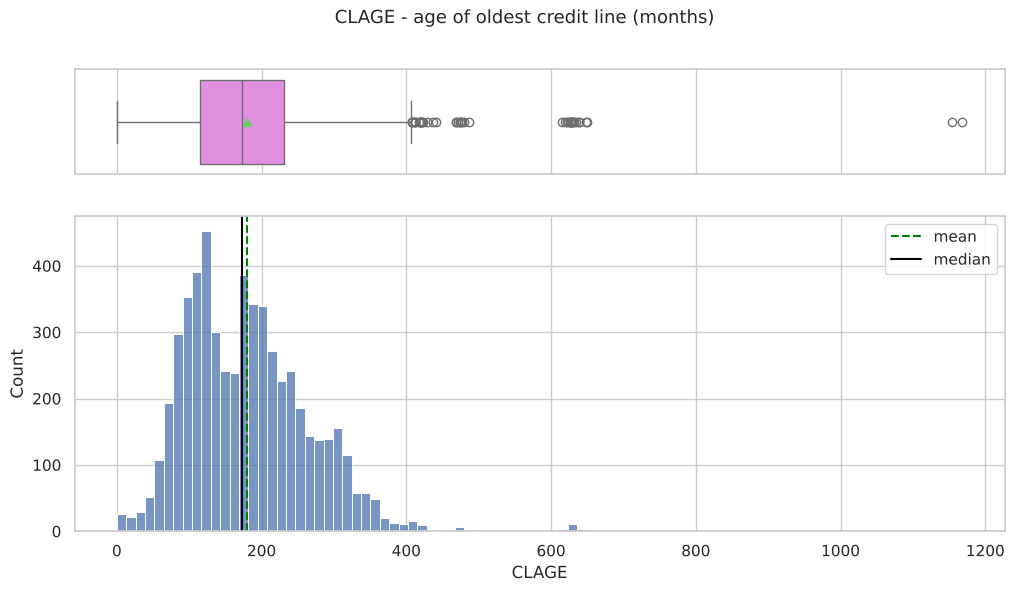

In [20]:
histogram_boxplot(data["CLAGE"], title="CLAGE - age of oldest credit line (months)")

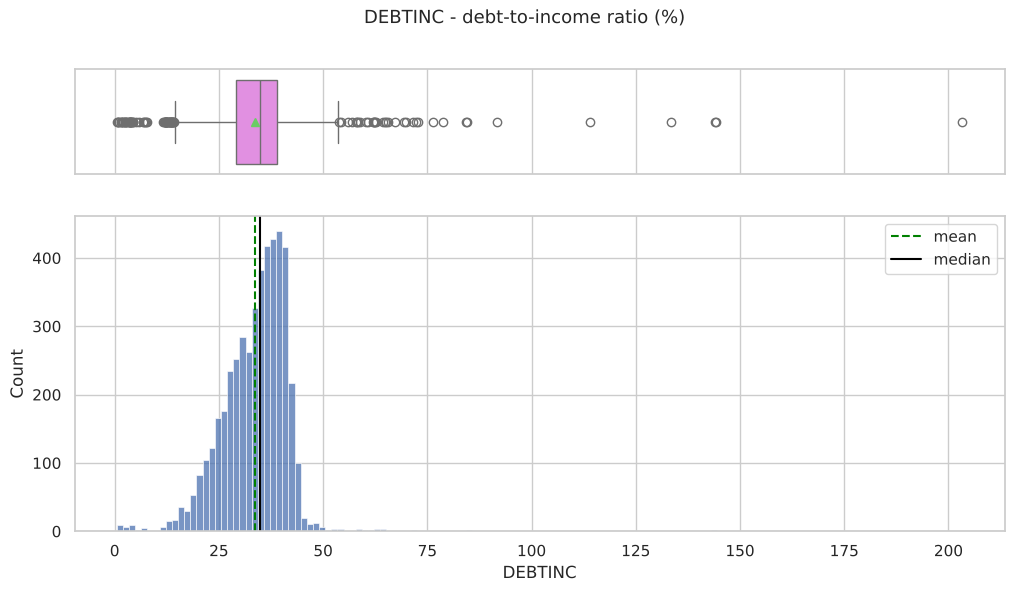

In [21]:
histogram_boxplot(data["DEBTINC"], title="DEBTINC - debt-to-income ratio (%)")

**Insights - CLAGE and DEBTINC:**
- `CLAGE` is roughly bell-shaped around 170-180 months (about 15 years of credit history) with a right tail. A handful of values above 600 months (50+ years) and a maximum of 1,168 months are not credible and will be capped for the linear model.
- `DEBTINC` is tightly concentrated between 25% and 42%; very few applicants have a recorded ratio above 45%. The maximum of 203% is an impossible value. Note that this plot only shows the 79% of applicants for whom the ratio is recorded.

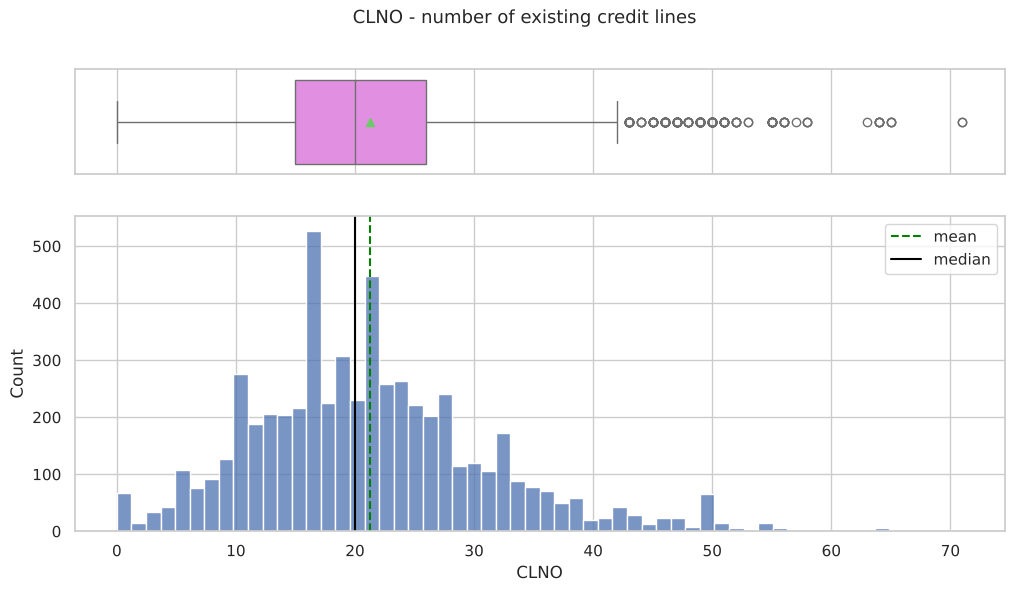

In [22]:
histogram_boxplot(data["CLNO"], title="CLNO - number of existing credit lines")

**Insights - CLNO:**
- Number of credit lines is approximately normal, centred around 20 lines, with a few applicants holding more than 45 lines.

#### Count-type variables (DEROG, DELINQ, NINQ)

These are whole-number counts where most applicants are at zero, so bar charts are more informative than histograms.

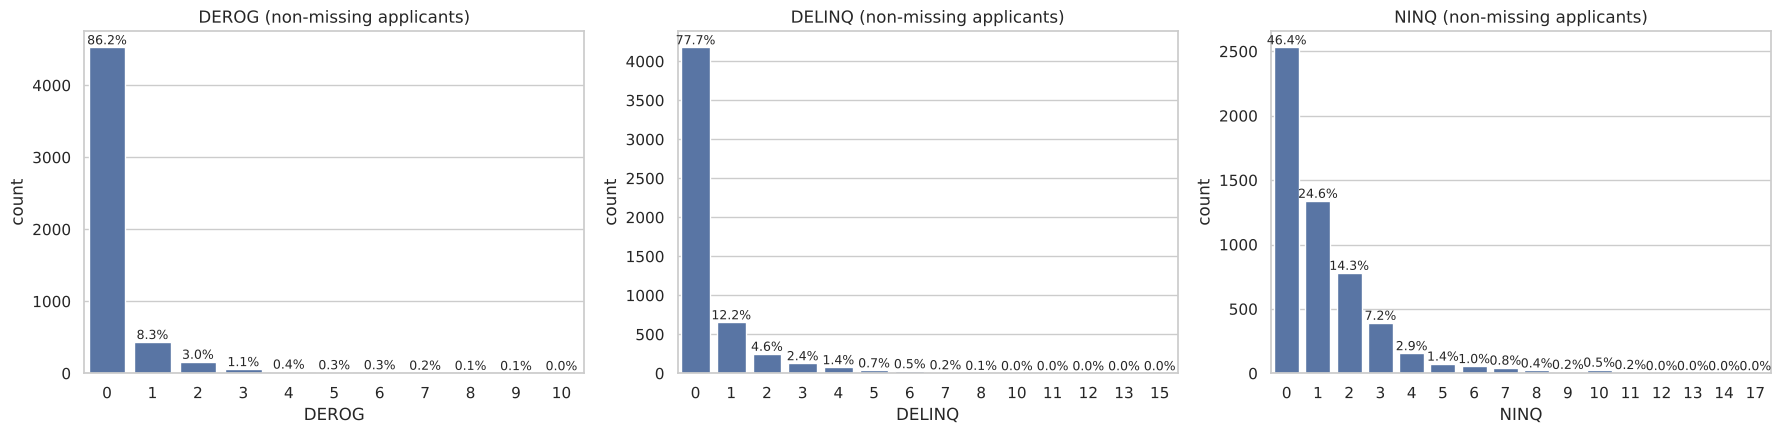

In [23]:
def perc_on_bar(ax, total):
    '''Annotate bars with the percentage of the total.'''
    for p in ax.patches:
        pct = f"{100 * p.get_height() / total:.1f}%"
        ax.annotate(pct, (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["DEROG", "DELINQ", "NINQ"]):
    s = data[col].dropna().astype(int)
    sns.countplot(x=s, ax=ax, color="#4C72B0")
    perc_on_bar(ax, len(s))
    ax.set_title(f"{col} (non-missing applicants)")
plt.tight_layout()
plt.show()

**Insights - DEROG, DELINQ, NINQ:**
- **86% of applicants have zero major derogatory reports** and 78% have zero delinquent credit lines. The minority with one or more is small but, as the bivariate analysis will show, carries a very high default rate.
- Recent credit inquiries are more spread out: 46% have none, 25% have one, 14% have two, and a tail have five or more. Many recent inquiries can signal a borrower actively seeking credit under financial stress.

#### Categorical variables (BAD, REASON, JOB)

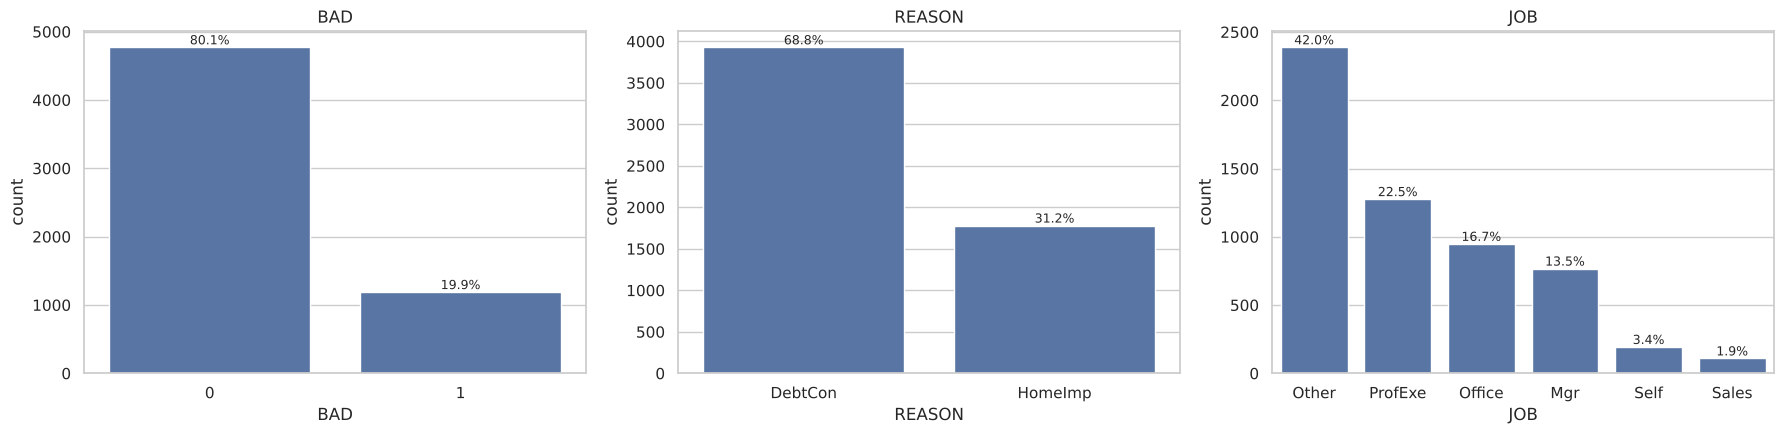

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["BAD", "REASON", "JOB"]):
    s = data[col].dropna()
    order = s.value_counts().index
    sns.countplot(x=s, order=order, ax=ax, color="#4C72B0")
    perc_on_bar(ax, len(s))
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Insights - BAD, REASON, JOB (Q3, Q4):**
- **Target:** 80% of loans were repaid and 20% defaulted. The imbalance is moderate, which is why we will use class weights in the models and recall, not accuracy, as the success metric.
- **REASON has 2 unique categories.** Debt consolidation (69%) is far more common than home improvement (31%).
- **JOB has 6 unique categories and "Other" is the most common (42%)**, followed by professional/executive (22%) and office workers (17%). Sales (2%) and self-employed (3%) are small groups, so default rates for them should be read with care.

### **Bivariate Analysis**

#### Numerical variables vs the target (BAD)

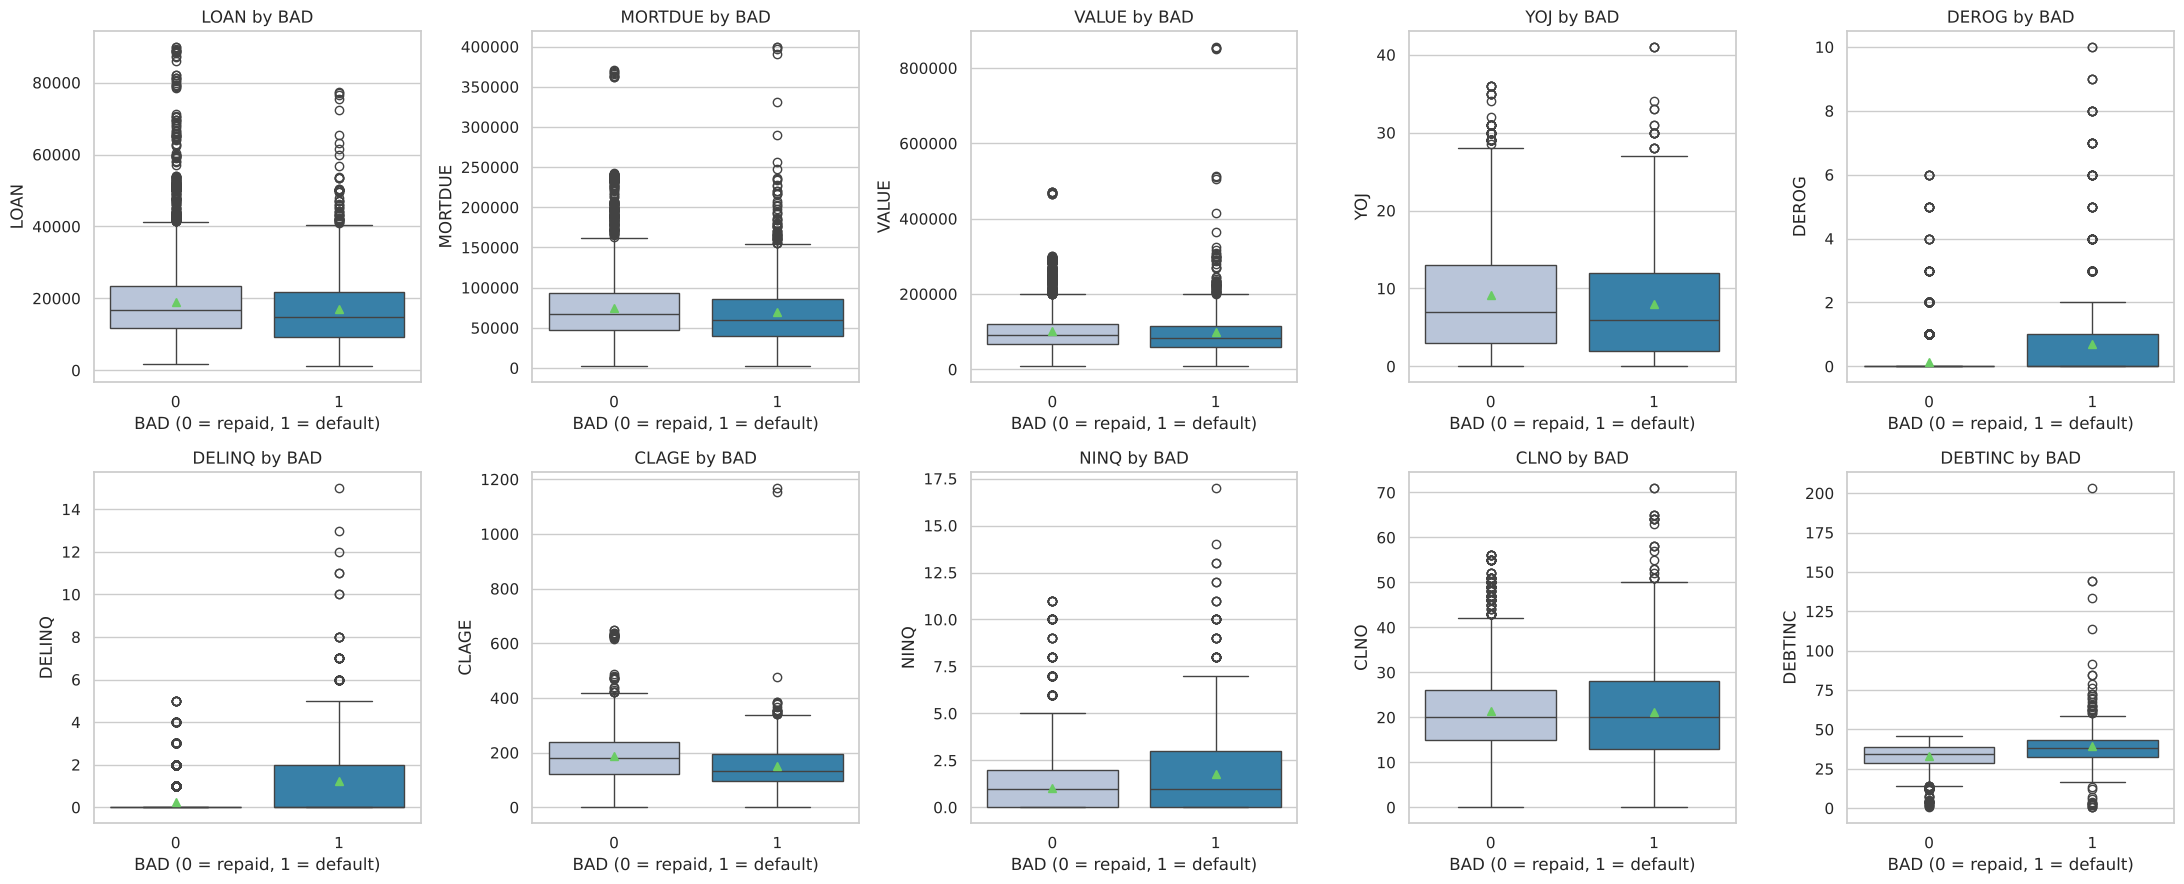

In [25]:
num_cols = ["LOAN", "MORTDUE", "VALUE", "YOJ", "DEROG", "DELINQ", "CLAGE", "NINQ", "CLNO", "DEBTINC"]

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x=data["BAD"], y=data[col], ax=ax, palette="PuBu", showmeans=True)
    ax.set_title(f"{col} by BAD")
    ax.set_xlabel("BAD (0 = repaid, 1 = default)")
plt.tight_layout()
plt.show()

In [26]:
# Mean and median of each numerical variable by target class
data.groupby("BAD", observed=True)[num_cols].agg(["mean", "median"]).T

BAD                      0          1
LOAN    mean    19,028.107 16,922.119
        median  16,900.000 14,900.000
MORTDUE mean    74,829.249 69,460.453
        median  66,839.000 60,279.000
VALUE   mean   102,595.921 98,172.846
        median  90,659.000 82,000.000
YOJ     mean         9.155      8.028
        median       7.000      6.000
DEROG   mean         0.134      0.708
        median       0.000      0.000
DELINQ  mean         0.245      1.229
        median       0.000      0.000
CLAGE   mean       187.002    150.190
        median     180.416    132.867
NINQ    mean         1.033      1.783
        median       1.000      1.000
CLNO    mean        21.317     21.211
        median      20.000     20.000
DEBTINC mean        33.253     39.388
        median      34.542     38.080

**Insights - numerical variables vs BAD (Q6, Q7, Q8):**

- **LOAN (Q6):** Defaulters borrowed *less* on average (mean \$16,922, median \$14,900) than repayers (mean \$19,028, median \$16,900). The difference is real but modest; loan size by itself is not a strong separator. The default rate by loan band (next chart) shows the pattern more clearly.
- **VALUE (Q7):** Defaulters have slightly lower property values (median \$82,000 vs \$90,659). The correlation between `VALUE` and `BAD` is weak (r = -0.03), so property value alone does not predict default; it matters in combination with the mortgage balance and the loan size.
- **MORTDUE (Q8):** Defaulters have a somewhat lower outstanding mortgage (median \$60,279 vs \$66,839). Again a modest difference.
- **DEROG and DELINQ** show the strongest separation: defaulters average 0.71 derogatory reports vs 0.13, and 1.23 delinquent lines vs 0.25. These are **5x higher** among defaulters.
- **CLAGE:** Defaulters have a materially shorter credit history (median 133 months vs 180 months). A long, established credit record is protective.
- **NINQ:** Defaulters made more recent inquiries (mean 1.78 vs 1.03).
- **DEBTINC:** Defaulters carry a higher debt burden (median 38.1% vs 34.5%) and the defaulter boxplot has a long upper tail where most of the extreme ratios sit.
- **YOJ and CLNO** show little difference between the two groups.

In [27]:
# Are the differences statistically significant? Mann-Whitney U tests for the amounts (robust to skew),
# chi-square tests of independence for the categorical variables.
rows = []
for col in ["LOAN", "MORTDUE", "VALUE", "DEBTINC", "CLAGE"]:
    a = data.loc[data["BAD"] == 1, col].dropna(); b = data.loc[data["BAD"] == 0, col].dropna()
    rows.append({"variable": col, "median_defaulters": a.median(), "median_repayers": b.median(),
                 "test": "Mann-Whitney U", "p_value": stats.mannwhitneyu(a, b).pvalue})
for col in ["REASON", "JOB"]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(data[col], data["BAD"]))
    rows.append({"variable": col, "median_defaulters": np.nan, "median_repayers": np.nan, "test": "Chi-square", "p_value": p})
pd.DataFrame(rows).style.format({"median_defaulters": "{:,.1f}", "median_repayers": "{:,.1f}", "p_value": "{:.2e}"})

,variable,median_defaulters,median_repayers,test,p_value
0,LOAN,"14,900.0","16,900.0",Mann-Whitney U,5.87e-17
1,MORTDUE,"60,279.0","66,839.0",Mann-Whitney U,1.61e-08
2,VALUE,"82,000.0","90,659.0",Mann-Whitney U,4.45e-09
3,DEBTINC,38.1,34.5,Mann-Whitney U,1.11e-23
4,CLAGE,132.9,180.4,Mann-Whitney U,1.45e-44
5,REASON,nan,nan,Chi-square,4.58e-03
6,JOB,nan,nan,Chi-square,3.31e-16


**Insights - significance tests (Q5, Q6, Q8):**
- The differences in `LOAN`, `MORTDUE` and `VALUE` between defaulters and repayers are **statistically significant** (p < 0.001 in each case, with 5,960 loans even modest gaps are detectable) but **small in practical terms**: medians differ by \$2,000 to \$9,000 on amounts of \$15,000 to \$90,000. `DEBTINC` and `CLAGE` differ both significantly and materially.
- `REASON` is related to default (chi-square p = 0.005) but the effect is weak (22.2% vs 19.0%); `JOB` is strongly related (p < 0.001).
- Statistical significance tells us the pattern is real; the band charts above tell us where it is large enough to act on.

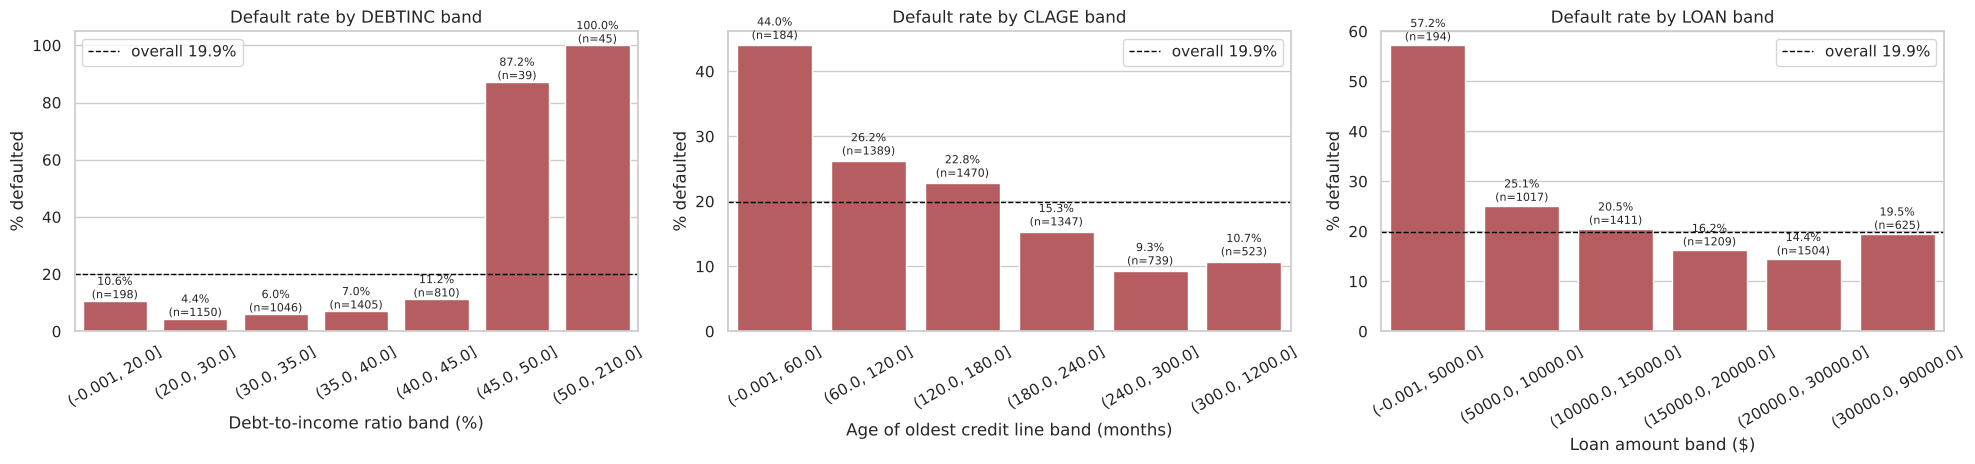

In [28]:
def default_rate_by_band(col, bins, labels=None):
    '''Default rate and applicant count per band of a numerical column (missing values excluded).'''
    banded = pd.cut(data[col], bins=bins, labels=labels, include_lowest=True)
    tab = data.groupby(banded, observed=True)["BAD"].agg(
        default_rate=lambda s: (s.astype(int).mean() * 100).round(1),
        applicants="count")
    return tab

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
specs = [
    ("DEBTINC", [0, 20, 30, 35, 40, 45, 50, 210], "Debt-to-income ratio band (%)"),
    ("CLAGE",   [0, 60, 120, 180, 240, 300, 1200], "Age of oldest credit line band (months)"),
    ("LOAN",    [0, 5000, 10000, 15000, 20000, 30000, 90000], "Loan amount band ($)"),
]
for ax, (col, bins, label) in zip(axes, specs):
    tab = default_rate_by_band(col, bins)
    sns.barplot(x=tab.index.astype(str), y=tab["default_rate"], ax=ax, color="#C44E52")
    for i, (rate, n) in enumerate(zip(tab["default_rate"], tab["applicants"])):
        ax.text(i, rate + 1, f"{rate}%\n(n={n})", ha="center", fontsize=8)
    ax.axhline(19.9, color="black", linestyle="--", linewidth=1, label="overall 19.9%")
    ax.set_title(f"Default rate by {col} band"); ax.set_xlabel(label); ax.set_ylabel("% defaulted")
    ax.tick_params(axis="x", rotation=30); ax.legend()
plt.tight_layout()
plt.show()

**Insights - default rate by band:**

- **DEBTINC is a cliff, not a slope.** Applicants with a recorded ratio between 20% and 40% default only 4% to 7% of the time, well below the 20% average (the small group below 20% is at 11%). Between 40% and 45% the rate is 11%, and **above 45% it jumps to 87%, and above 50% to 100%**. A debt-to-income threshold around 45% is therefore a natural, explainable approval rule.
- **CLAGE protects.** Applicants whose oldest credit line is under 5 years old default 44% of the time; the rate falls steadily to 9% to 11% once the credit history is longer than 20 years.
- **Small loans are the riskiest.** Loans under \$5,000 default 57% of the time, against 14% to 20% for loans above \$15,000. Small loans may be requested by financially stretched applicants, or the bank may already be limiting exposure to weaker applicants. Either way, a small requested amount is not a sign of low risk.

#### Categorical and count variables vs the target (BAD)

In [29]:
def stacked_plot(x, title=None):
    '''Cross-tab counts and a normalised stacked bar chart of BAD by a categorical column.'''
    tab_counts = pd.crosstab(x, data["BAD"], margins=True)
    print(tab_counts)
    print("-" * 60)
    tab = pd.crosstab(x, data["BAD"], normalize="index")
    ax = tab.plot(kind="bar", stacked=True, figsize=(9, 4), color=["#4C72B0", "#C44E52"])
    for i, (idx, row) in enumerate(tab.iterrows()):
        ax.text(i, 1.01, f"{row[1]*100:.0f}% bad", ha="center", fontsize=9)
    ax.legend(title="BAD", loc="upper left", bbox_to_anchor=(1, 1))
    ax.set_ylabel("share of applicants")
    ax.set_title(title or f"BAD by {x.name}")
    plt.show()

BAD         0     1   All
REASON                   
DebtCon  3183   745  3928
HomeImp  1384   396  1780
All      4567  1141  5708
------------------------------------------------------------


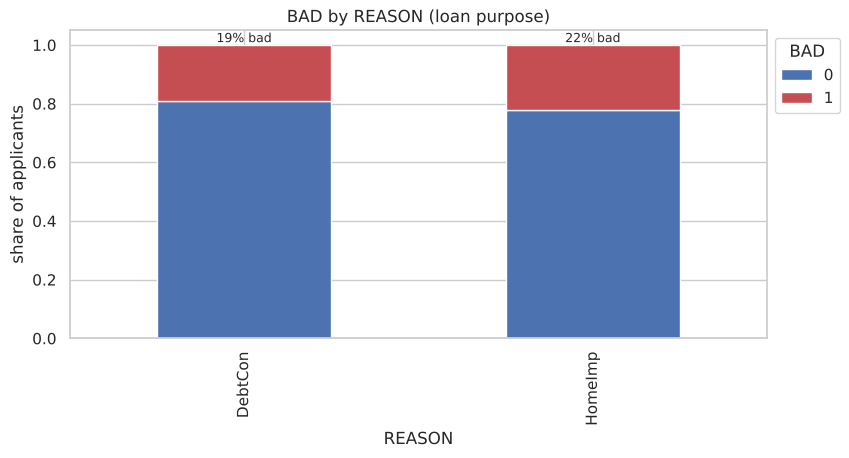

In [30]:
stacked_plot(data["REASON"], "BAD by REASON (loan purpose)")

**Insights - REASON vs BAD (Q5):**
- Home-improvement loans default slightly more often (**22.2%**) than debt-consolidation loans (**19.0%**). There is a relationship, but it is weak: a 3-point difference around a 20% base rate. Loan purpose on its own should not drive approval decisions.

BAD         0     1   All
JOB                      
Mgr       588   179   767
Office    823   125   948
Other    1834   554  2388
ProfExe  1064   212  1276
Sales      71    38   109
Self      135    58   193
All      4515  1166  5681
------------------------------------------------------------


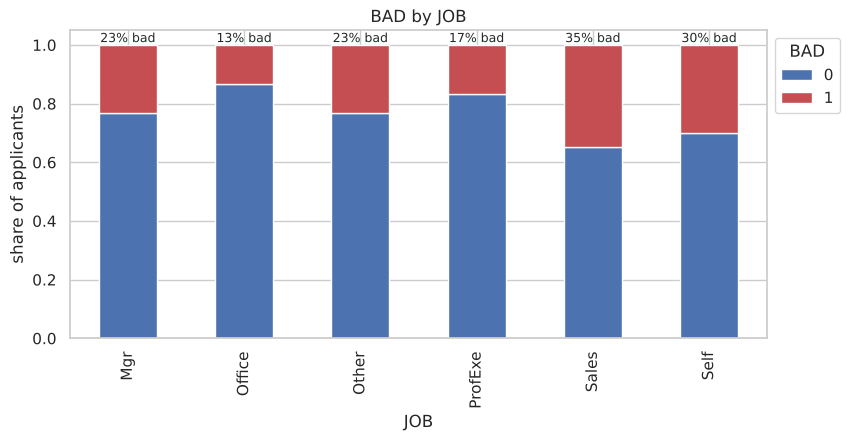

In [31]:
stacked_plot(data["JOB"], "BAD by JOB")

**Insights - JOB vs BAD:**
- Default risk varies clearly by occupation. **Sales (34.9%)** and **Self-employed (30.1%)** applicants default at 1.5x to 1.75x the average, consistent with more variable income. **Office workers (13.2%)** and **professionals/executives (16.6%)** are the safest groups; managers (23.3%) and "Other" (23.2%) sit slightly above average.
- The Sales and Self groups are small (109 and 193 applicants), so the model should use occupation as a supporting signal, not a primary one. Note also that occupation must be used carefully under fair-lending rules; it is not a protected attribute, but the bank should monitor it for proxy effects.

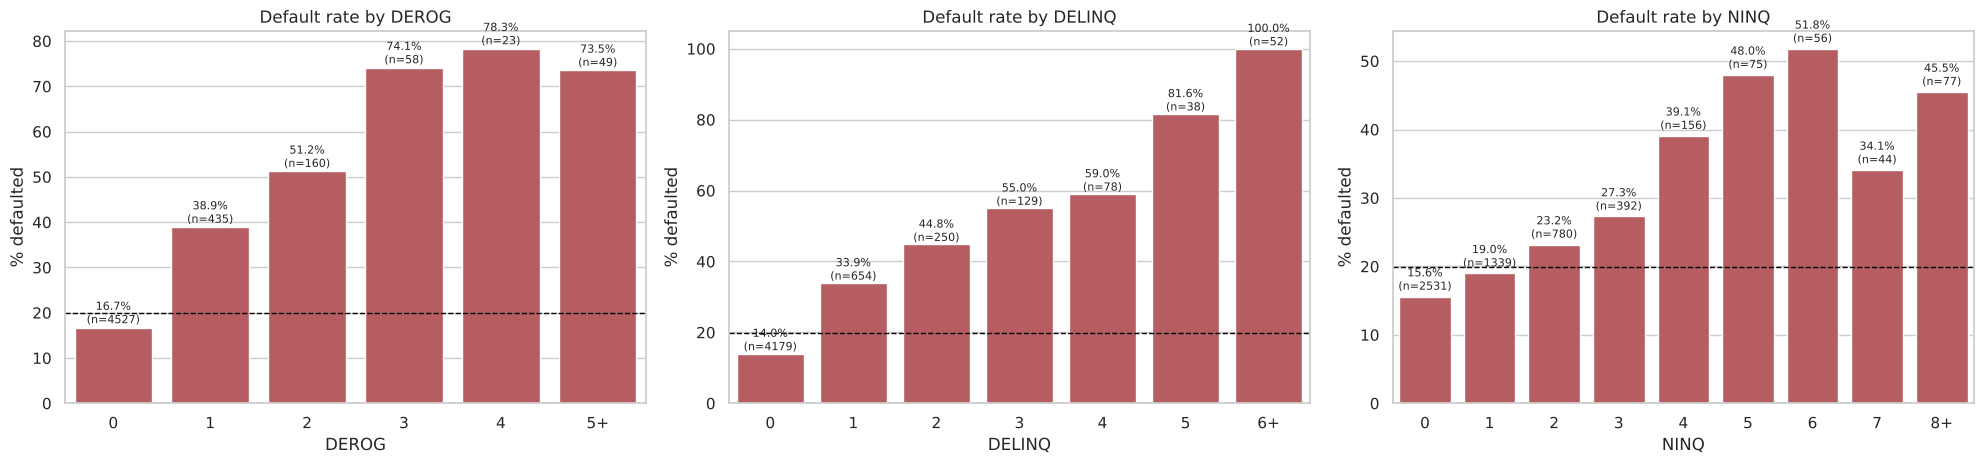

In [32]:
# Default rate by number of derogatory reports, delinquent lines and recent inquiries (capped for readability)
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
for ax, (col, cap) in zip(axes, [("DEROG", 5), ("DELINQ", 6), ("NINQ", 8)]):
    s = data[col].clip(upper=cap)
    tab = data.groupby(s, observed=True)["BAD"].agg(
        default_rate=lambda v: (v.astype(int).mean() * 100).round(1), applicants="count")
    labels = [f"{int(i)}+" if i == cap else f"{int(i)}" for i in tab.index]
    sns.barplot(x=labels, y=tab["default_rate"], ax=ax, color="#C44E52")
    for i, (rate, n) in enumerate(zip(tab["default_rate"], tab["applicants"])):
        ax.text(i, rate + 1, f"{rate}%\n(n={n})", ha="center", fontsize=8)
    ax.axhline(19.9, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Default rate by {col}"); ax.set_ylabel("% defaulted"); ax.set_xlabel(col)
plt.tight_layout()
plt.show()

**Insights - credit-history counts vs BAD:**

- **DEROG:** Applicants with no derogatory report default 16.7% of the time. **One report raises this to 39%, two to 51%, three or four to about 75%, and five or more to 73%** (the small groups at the top are noisy, but every one of them is far above average).
- **DELINQ:** The pattern is the same and even steeper: 14% with no delinquent line, 34% with one, 45% with two, 55% with three, and **100% with six or more**.
- **NINQ:** Default risk rises with recent inquiries: 16% at zero, 23% at two, 39% at four, and around 45-50% at five or more.
- All three rise with the count, are easy to explain to an applicant ("your application was declined because you have two delinquent credit lines") and are exactly the kind of evidence the ECOA asks for.

#### Does missing information predict default?

In [33]:
# Default rate when a field is missing vs when it is present
rows = []
for col in data.columns.drop("BAD"):
    if data[col].isnull().any():
        is_na = data[col].isnull()
        rows.append({
            "column": col,
            "missing_rows": int(is_na.sum()),
            "default_rate_when_missing_%": round(data.loc[is_na, "BAD"].astype(int).mean() * 100, 1),
            "default_rate_when_present_%": round(data.loc[~is_na, "BAD"].astype(int).mean() * 100, 1),
        })
missing_vs_bad = pd.DataFrame(rows).sort_values("default_rate_when_missing_%", ascending=False)
missing_vs_bad

,column,missing_rows,default_rate_when_missing_%,default_rate_when_present_%
1,VALUE,112,93.800,18.500
10,DEBTINC,1267,62.000,8.600
7,CLAGE,308,25.300,19.700
9,CLNO,222,23.900,19.800
0,MORTDUE,518,20.500,19.900
2,REASON,252,19.000,20.000
8,NINQ,510,14.700,20.400
4,YOJ,515,12.600,20.600
6,DELINQ,580,12.400,20.800
5,DEROG,708,12.300,21.000


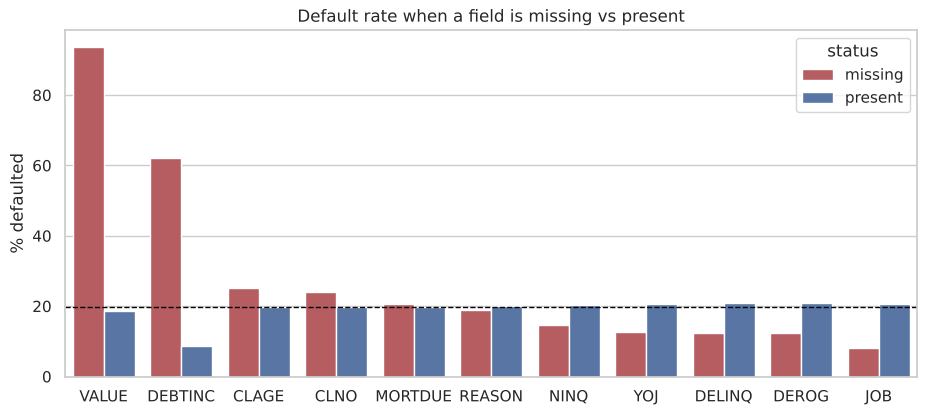

In [34]:
plt.figure(figsize=(11, 4.5))
m = missing_vs_bad.melt(id_vars="column", value_vars=["default_rate_when_missing_%", "default_rate_when_present_%"],
                        var_name="status", value_name="default_rate")
m["status"] = m["status"].str.replace("default_rate_when_", "").str.replace("_%", "")
sns.barplot(data=m, x="column", y="default_rate", hue="status", palette=["#C44E52", "#4C72B0"])
plt.axhline(19.9, color="black", linestyle="--", linewidth=1)
plt.title("Default rate when a field is missing vs present")
plt.ylabel("% defaulted"); plt.xlabel("")
plt.show()

**Insights - missingness as a signal (a key finding):**

- **When DEBTINC is missing, 62% of applicants defaulted; when it is present, only 8.6% did.** A missing debt-to-income ratio is the single strongest risk indicator in the whole dataset. In practice, applicants whose income could not be verified, or who did not supply it, are far riskier than those with a verified ratio.
- **When VALUE is missing, 94% defaulted** (112 applicants). An application without a property valuation is almost always bad.
- Missing `CLAGE` (25%) and `CLNO` (24%) are mildly riskier than average.
- The opposite holds for `DEROG`, `DELINQ`, `YOJ`, `NINQ` and `JOB`: when these are missing the default rate is *lower* (8% to 15%). This probably reflects how the data was recorded (for example, "no record found" stored as blank for good customers).
- **Implication for pre-processing:** we must not simply fill these gaps with the median and move on. We will **add a binary "was missing" flag for every column with gaps** so the models can learn from the absence of information, and then impute the values.

#### Two numerical variables together

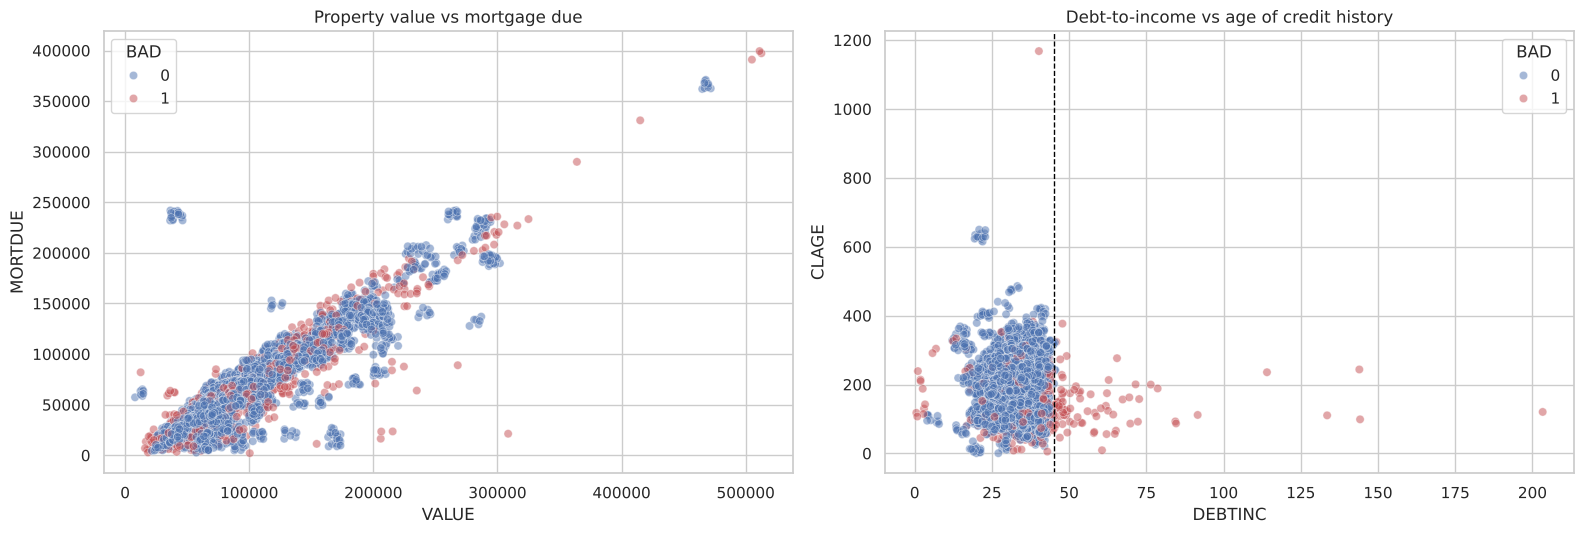

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(data=data, x="VALUE", y="MORTDUE", hue="BAD", alpha=0.5, ax=axes[0], palette=["#4C72B0", "#C44E52"])
axes[0].set_title("Property value vs mortgage due")
sns.scatterplot(data=data, x="DEBTINC", y="CLAGE", hue="BAD", alpha=0.5, ax=axes[1], palette=["#4C72B0", "#C44E52"])
axes[1].axvline(45, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Debt-to-income vs age of credit history")
plt.tight_layout()
plt.show()

**Insights:**
- `VALUE` and `MORTDUE` lie close to a straight line: the mortgage balance is typically 60% to 80% of the property value. Defaulters are scattered throughout rather than clustered, confirming that these two amounts alone do not separate the classes.
- In the right-hand chart almost every applicant to the right of the 45% debt-to-income line is a defaulter, regardless of credit history length. To the left, defaulters are concentrated in the lower part of the chart (short credit history). The two variables complement each other.

### **Multivariate Analysis**

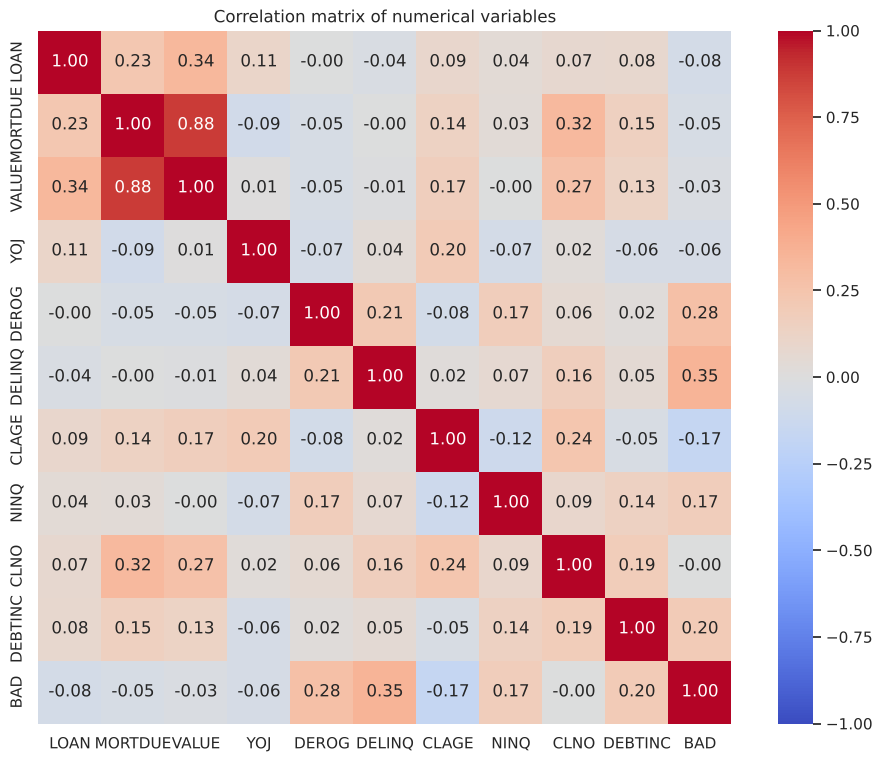

In [36]:
# Correlation heatmap for numerical variables (target included as a number)
corr_df = data[num_cols].copy()
corr_df["BAD"] = data["BAD"].astype(int)
corr = corr_df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix of numerical variables")
plt.show()

**Insights - correlations:**
- The only strong correlation between inputs is **MORTDUE vs VALUE (0.88)**. For the logistic regression this is multicollinearity: the two coefficients will share the same information and individually be less reliable. Tree-based models are unaffected.
- Moderate relationships: `CLNO` with `MORTDUE`/`VALUE` (0.27 to 0.32, wealthier borrowers hold more credit lines) and `LOAN` with `VALUE` (0.34).
- Correlations with the target are weak to moderate: `DELINQ` (0.35) and `DEROG` (0.28) are the highest, followed by `DEBTINC` (0.20), `NINQ` (0.17) and `CLAGE` (-0.17). The count variables are close to linear in the default rate, but the band charts showed that `DEBTINC`, `CLAGE` and `LOAN` act through thresholds and cliffs that a single correlation coefficient understates. This is an early hint that **tree-based models, which capture thresholds naturally, should outperform a purely linear model on the raw inputs**.

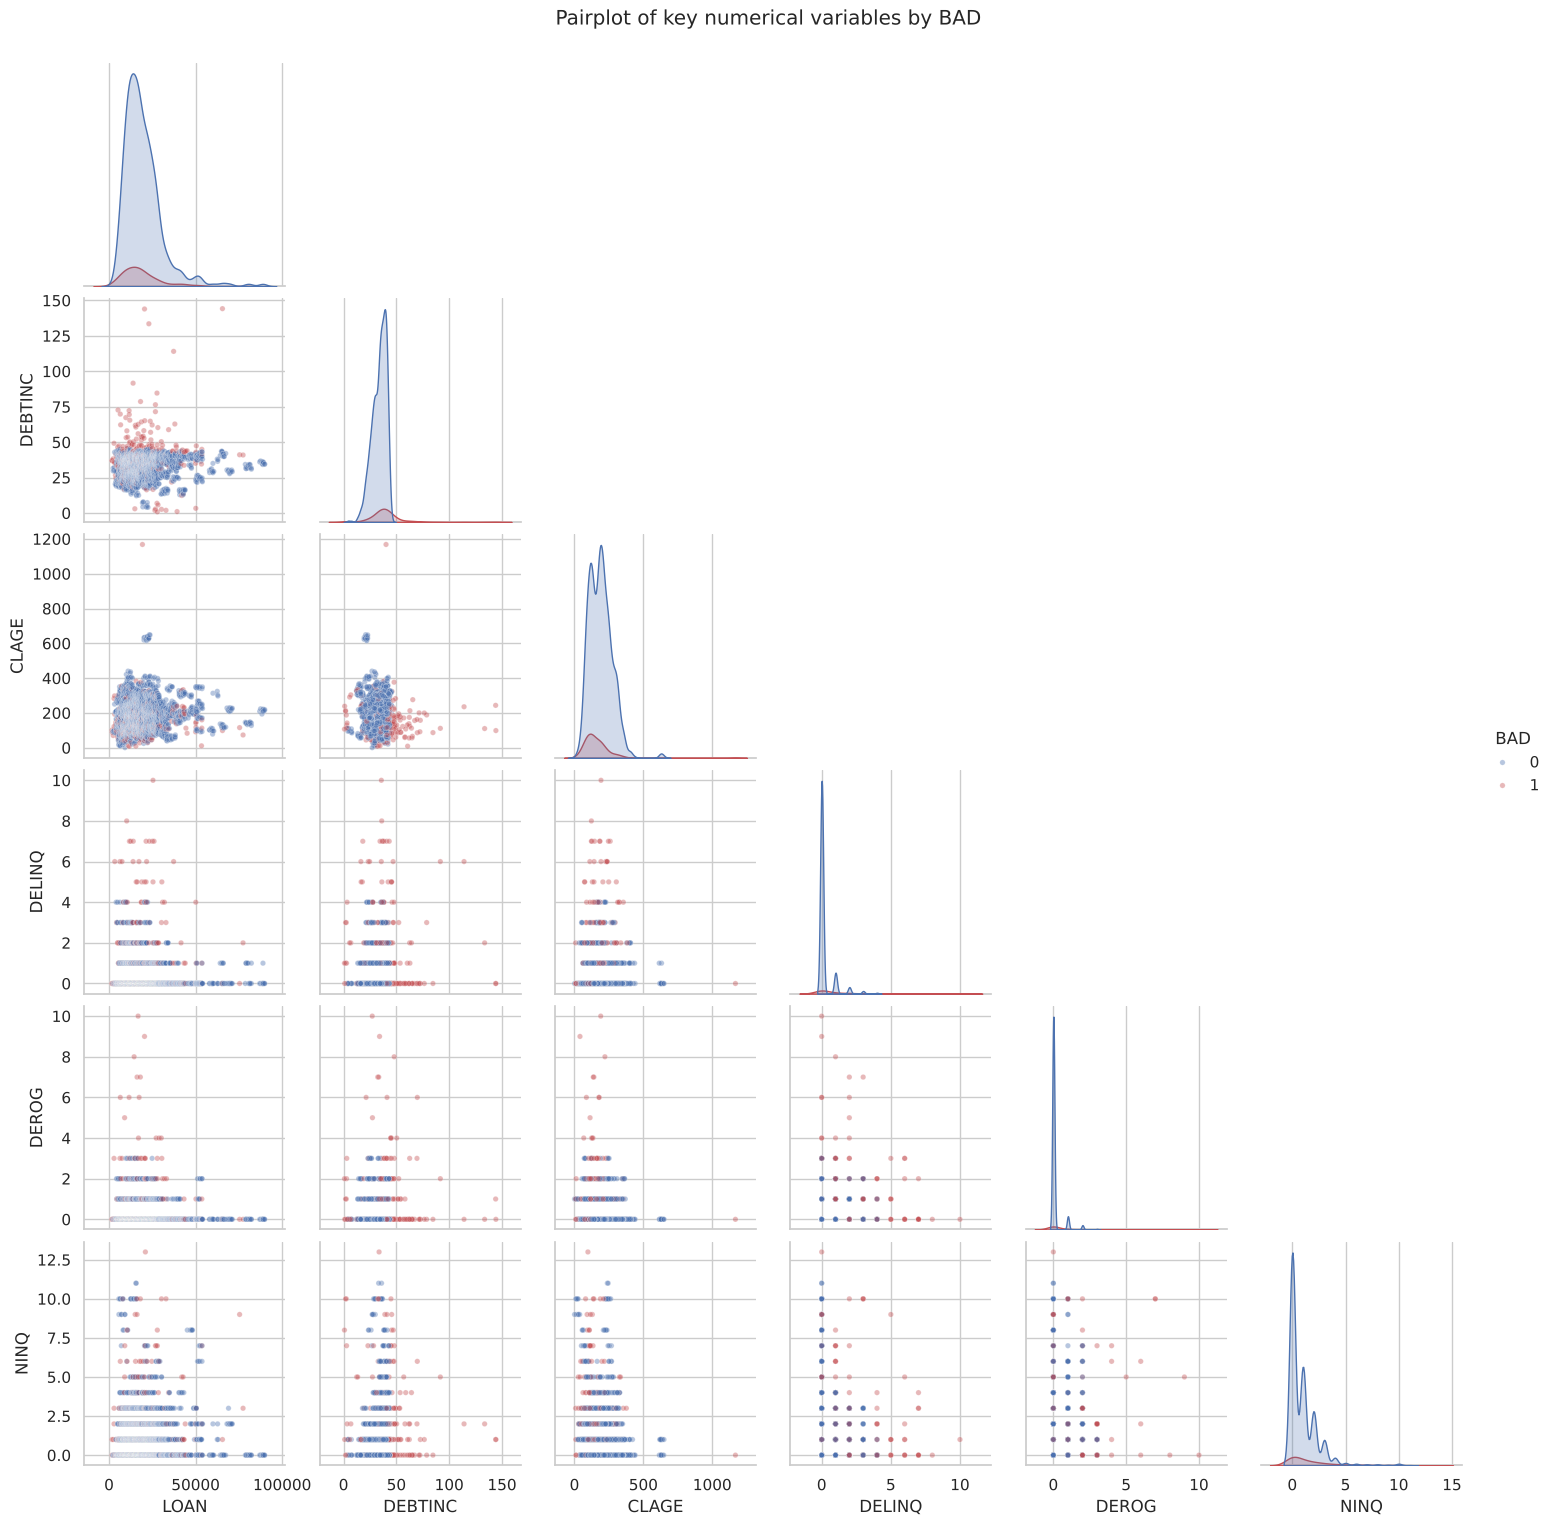

In [37]:
# Pairplot of the most informative numerical variables, coloured by the target
sns.pairplot(data[["LOAN", "DEBTINC", "CLAGE", "DELINQ", "DEROG", "NINQ", "BAD"]].dropna(),
             hue="BAD", palette=["#4C72B0", "#C44E52"], diag_kind="kde", corner=True,
             plot_kws={"alpha": 0.4, "s": 15})
plt.suptitle("Pairplot of key numerical variables by BAD", y=1.02)
plt.show()

**Insights - pairplot:**
- The density curves on the diagonal show that defaulters (red) have visibly shorter `CLAGE`, higher `DEBTINC` and heavier tails on `DELINQ`, `DEROG` and `NINQ`.
- No single pair of variables separates the classes cleanly; the separation comes from combinations, which again favours tree-based models.

## Hold out the test set before fitting any pre-processing

Every statistic used to prepare the data (outlier fences, imputation medians and modes, feature scaling) is **fitted on the training rows only** and then applied to the test rows. Fitting them on all 5,960 loans would leak a little information about the test applicants into the model. The split is 70% train / 30% test, stratified on `BAD` so both sets keep the 20% default rate, with a fixed seed so every model sees the same applicants.

In [38]:
train_idx, test_idx = train_test_split(data.index, test_size=0.30, random_state=RANDOM_STATE, stratify=data["BAD"])
print(f"Training rows: {len(train_idx):,} | Test rows: {len(test_idx):,}")
print(f"Default rate - train: {data.loc[train_idx, 'BAD'].astype(int).mean():.3f}, test: {data.loc[test_idx, 'BAD'].astype(int).mean():.3f}")

Training rows: 4,172 | Test rows: 1,788
Default rate - train: 0.199, test: 0.200


## Treating Outliers

**Approach.** The boxplots showed outliers in almost every numerical column. Two kinds exist here:

1. *Implausible values* that are probably data errors: `DEBTINC` above 100%, `CLAGE` above about 600 months.
2. *Genuine but extreme values*: large loans, expensive properties, many delinquencies.

Both kinds matter differently for different models:

- **Logistic Regression** is sensitive to extreme values because they pull the fitted line. For the linear model we **cap** each continuous column at the IQR whiskers (Q1 - 1.5 IQR and Q3 + 1.5 IQR), which keeps every row but limits the leverage of extremes. The count variables `DEROG` and `DELINQ` are capped at their 99th percentile instead, because their inter-quartile range is zero. All fences are computed on the training rows.
- **Decision Trees and Random Forests** split on rank order, so an outlier simply falls into the top bucket; capping does not change their splits. For the tree models we **keep the original values**, which also preserves information such as "DEBTINC above 50% almost always defaults".

We therefore keep two versions of the data: `df_lr` (outliers capped, for the linear model) and `data` (untreated, for the tree models).

In [39]:
def treat_outliers(df, col, fit_rows):
    '''Cap a numerical column at the IQR whiskers computed on the training rows.'''
    Q1 = df.loc[fit_rows, col].quantile(0.25)
    Q3 = df.loc[fit_rows, col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    df[col] = np.clip(df[col], lower, upper)
    return df

def treat_outliers_all(df, col_list, fit_rows):
    for c in col_list:
        df = treat_outliers(df, c, fit_rows)
    return df

df_lr = data.copy()

# IQR capping for the continuous variables
iqr_cols = [c for c in num_cols if c not in ("DEROG", "DELINQ")]
df_lr = treat_outliers_all(df_lr, iqr_cols, train_idx)

# DEROG and DELINQ are counts with Q1 = Q3 = 0, so the IQR whiskers collapse to zero and would erase
# the variables entirely. They are capped at the 99th percentile (of the training rows) instead.
for c in ["DEROG", "DELINQ"]:
    df_lr[c] = df_lr[c].clip(upper=df_lr.loc[train_idx, c].quantile(0.99))

# Compare the maximum of each column before and after capping
pd.DataFrame({"max_before": data[num_cols].max(), "max_after": df_lr[num_cols].max(),
              "rows_capped": [(data[c] > df_lr[c]).sum() + (data[c] < df_lr[c]).sum() for c in num_cols]})

,max_before,max_after,rows_capped
LOAN,"89,900.000","41,850.000",249
MORTDUE,"399,550.000","161,277.500",227
VALUE,"855,909.000","201,864.750",307
YOJ,41.000,28.000,91
DEROG,10.000,5.000,34
DELINQ,15.000,6.000,25
CLAGE,"1,168.234",406.840,47
NINQ,17.000,5.000,177
CLNO,71.000,46.500,155
DEBTINC,203.312,53.785,94


**Observations:**
- Capping removes the impossible values (DEBTINC 203% becomes about 54%, CLAGE 1,168 months becomes about 407 months) while keeping every row.
- `DEROG` and `DELINQ` have a 75th percentile of zero, so the IQR whiskers collapse to zero; applying the rule blindly would set every value to zero and erase two of the strongest risk signals. They are therefore capped at the 99th percentile instead (about 5 derogatory reports and 6 delinquent lines), which limits the leverage of the extreme counts while keeping the signal.
- The capped DEBTINC ceiling (about 54%) is still above the 45% danger threshold, so the linear model can still learn that rule.

## Treating Missing Values

**Approach.**

1. **Create a binary flag** `<column>_missing` for every column with gaps. The bivariate analysis showed that missingness, especially of `DEBTINC` and `VALUE`, is strongly predictive, so this information must be preserved.
2. **Impute numerical columns with the median** (robust to the skew and outliers seen above) and **categorical columns with the mode**, both computed on the training rows only and applied to all rows.
3. Apply exactly the same steps to both versions of the data (`df_lr` for the linear model, `data` for the tree models).

In [40]:
def add_missing_flags(df):
    '''Add a 0/1 flag column for each column that has missing values.'''
    for col in [c for c in df.columns if df[c].isnull().any()]:
        df[f"{col}_missing"] = df[col].isnull().astype(int)
    return df

def impute(df, fit_rows):
    '''Median for numerical columns, mode for categorical columns, both learned from the training rows.'''
    num = df.select_dtypes("number").columns
    cat = df.select_dtypes("category").columns.drop("BAD")
    df[num] = df[num].fillna(df.loc[fit_rows, num].median())
    for c in cat:
        df[c] = df[c].fillna(df.loc[fit_rows, c].mode()[0])
    return df

for frame in (df_lr, data):
    add_missing_flags(frame)
    impute(frame, train_idx)

print("Remaining missing values (tree data):", data.isnull().sum().sum())
print("Remaining missing values (linear data):", df_lr.isnull().sum().sum())
print("\nFlag columns added:", [c for c in data.columns if c.endswith("_missing")])

Remaining missing values (tree data): 0
Remaining missing values (linear data): 0

Flag columns added: ['MORTDUE_missing', 'VALUE_missing', 'REASON_missing', 'JOB_missing', 'YOJ_missing', 'DEROG_missing', 'DELINQ_missing', 'CLAGE_missing', 'NINQ_missing', 'CLNO_missing', 'DEBTINC_missing']


In [41]:
data.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC,MORTDUE_missing,VALUE_missing,REASON_missing,JOB_missing,YOJ_missing,DEROG_missing,DELINQ_missing,CLAGE_missing,NINQ_missing,CLNO_missing,DEBTINC_missing
0,1,1100,"25,860.000","39,025.000",HomeImp,Other,10.500,0.000,0.000,94.367,1.000,9.000,34.840,0,0,0,0,0,0,0,0,0,0,1
1,1,1300,"70,053.000","68,400.000",HomeImp,Other,7.000,0.000,2.000,121.833,0.000,14.000,34.840,0,0,0,0,0,0,0,0,0,0,1
2,1,1500,"13,500.000","16,700.000",HomeImp,Other,4.000,0.000,0.000,149.467,1.000,10.000,34.840,0,0,0,0,0,0,0,0,0,0,1
3,1,1500,"66,293.000","89,965.000",DebtCon,Other,7.000,0.000,0.000,173.868,1.000,20.000,34.840,1,1,1,1,1,1,1,1,1,1,1
4,0,1700,"97,800.000","112,000.000",HomeImp,Office,3.000,0.000,0.000,93.333,0.000,14.000,34.840,0,0,0,0,0,0,0,0,0,0,1


## **Important Insights from EDA**

What are the the most important observations and insights from the data based on the EDA performed?

1. **One in five loans goes bad (19.9%).** The classes are imbalanced, so accuracy is the wrong yardstick and class weights are needed during training.

2. **Missing information is the strongest single risk signal.** Applicants with no recorded debt-to-income ratio default 62% of the time (vs 8.6% when it is recorded) and applicants with no property valuation default 94% of the time. The bank's approval process should treat an unverifiable income or valuation as a red flag, not as a neutral gap.

3. **Debt-to-income ratio has a hard threshold.** Between 20% and 40% the default rate is only 4% to 7% (and 11% below 20%); between 40% and 45% it is 11%; above 45% it is 87% to 100%. A 45% cut-off is a simple, defensible policy rule.

4. **Past credit behaviour predicts future behaviour.** Each additional major derogatory report or delinquent credit line raises the default rate sharply (0 reports: 17%; 1: 39%; 2: 51%; 3 or more: about 75%). Recent credit inquiries show the same rising pattern.

5. **A long credit history protects.** Applicants whose oldest credit line is under 5 years old default 44% of the time; above 20 years the rate falls to about 10%.

6. **Small loans are not safe loans.** Loans under \$5,000 default 57% of the time, almost three times the average.

7. **Occupation matters moderately.** Sales (35%) and self-employed (30%) applicants default most; office workers (13%) and professionals (17%) least. Loan purpose (home improvement vs debt consolidation) makes only a 3-point difference, although the difference is statistically significant.

8. **Property value and mortgage balance are highly correlated (0.88)** and individually weak predictors. They will be kept, but the linear model's coefficients for them should be read with caution.

9. **Several relationships with the target are threshold-shaped** (debt-to-income, credit-history length, loan size) rather than straight lines, so tree-based models are expected to outperform logistic regression on the raw inputs, while logistic regression will remain useful as the most transparent benchmark.

10. **Pre-processing decisions:** no rows dropped, no duplicates found, the test set held out before any statistic was fitted, a missing-value flag added for every column with gaps, median/mode imputation learned on the training rows, IQR capping only for the linear model (99th-percentile cap for the two count variables), one-hot encoding for `REASON` and `JOB`, and feature scaling of the continuous inputs only for the linear model.

## **Model Building - Approach**
- Data preparation
- Partition the data into train and test set
- Build the model
- Fit on the train data
- Tune the model
- Test the model on test set

**A note on technique choice.** The Practical Data Science toolkit covers decision trees, bagging and random forests, and time-series forecasting. The first three are used below, building up from a single tree to a bagged ensemble to a random forest so that the contribution of each idea is visible. Time-series methods do not apply to this problem: each row is one loan application with no date or ordering, so there is no sequence to model. A time-aware validation (train on earlier applications, test on later ones) is recommended as further analysis once application dates are available. Logistic regression is included as the linear benchmark required for a fair comparison of linear and non-linear techniques.

**How the test set is used.** Hyper-parameters, the final model and its decision threshold are all chosen with cross-validation on the training rows. The test set is scored once per model to report performance and is never used to make a choice.

### Model evaluation criterion - what is the measure of success?

The model makes two kinds of mistakes, and they do not cost the same:

| Model says | Reality | Name | Business consequence |
|---|---|---|---|
| Will repay (approve) | Defaults | **False Negative** | The bank loses a large part of the principal plus collection costs. The defaulted loans in this data averaged about \$16,900; with about half recovered through the collateral, roughly \$9,000 per missed defaulter. |
| Will default (reject) | Would have repaid | **False Positive** | The bank loses the interest margin on one good customer and may lose the relationship. Roughly \$2,000. |

A missed defaulter costs several times more than a wrongly rejected good customer. The primary metric is therefore **Recall on the defaulter class (BAD = 1)**: *of all the applicants who went on to default, what share did the model flag in advance?*

Recall alone can be gamed (rejecting everyone gives 100% recall), so we track two guard-rails:

- **Precision** on the defaulter class: of the applicants we reject, how many would really have defaulted? Low precision means the bank is turning away good business.
- **F1-score**: the harmonic mean of the two, used as the tie-breaker when recall is similar.

We also report **Accuracy** for completeness and **ROC-AUC** as a threshold-free measure of how well the model ranks risky applicants, which matters because the bank can later move the decision threshold.

The individual models are tuned with **cross-validated grid search optimising Recall** (the course convention, and a deliberate push towards catching defaulters). Because recall alone rewards flagging everyone, the **final model and its threshold are then chosen on the expected cost of the two errors**, estimated with out-of-fold predictions on the training rows, so that precision is priced in explicitly.

In [42]:
def metrics_score(actual, predicted, labels=("Repaid (0)", "Default (1)"), title="Confusion matrix"):
    '''Classification report and a confusion matrix heatmap.'''
    print(classification_report(actual, predicted, digits=3))
    cm = confusion_matrix(actual, predicted)
    plt.figure(figsize=(5.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels)
    plt.ylabel("Actual"); plt.xlabel("Predicted"); plt.title(title)
    plt.show()


def model_scores(model, X_tr, y_tr, X_te, y_te, name):
    '''Return a one-row DataFrame of train/test metrics for a fitted model.'''
    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    row = {
        "Model": name,
        "Train Recall": recall_score(y_tr, p_tr), "Test Recall": recall_score(y_te, p_te),
        "Train Precision": precision_score(y_tr, p_tr), "Test Precision": precision_score(y_te, p_te),
        "Train F1": f1_score(y_tr, p_tr), "Test F1": f1_score(y_te, p_te),
        "Train Accuracy": accuracy_score(y_tr, p_tr), "Test Accuracy": accuracy_score(y_te, p_te),
        "Test ROC-AUC": roc_auc_score(y_te, model.predict_proba(X_te)[:, 1]),
    }
    return pd.DataFrame([row])

results = []   # collects the comparison table

### Data preparation and train/test split

- Separate the target from the inputs, one-hot encode `REASON` and `JOB` (dropping the first level to avoid redundant columns), and convert the target to integer.
- Use the **70% / 30% stratified split** fixed above (`train_idx`, `test_idx`) for both data versions, so **the same applicants end up in the test set** for the linear and the tree models.
- Standardise the **continuous inputs only** for the linear model (fit on the training rows). The 0/1 flags and dummy columns are left as they are, so each of their coefficients can be read as the effect of the flag switching from 0 to 1.

In [43]:
def prepare_xy(df):
    X = pd.get_dummies(df.drop(columns=["BAD"]), columns=["REASON", "JOB"], drop_first=True, dtype=int)
    y = df["BAD"].astype(int)
    return X, y

# Linear-model version (outliers capped)
X_lr, y_lr = prepare_xy(df_lr)
X_train_lr, X_test_lr = X_lr.loc[train_idx], X_lr.loc[test_idx]
y_train_lr, y_test_lr = y_lr.loc[train_idx], y_lr.loc[test_idx]

# Tree-model version (outliers untouched)
X, y = prepare_xy(data)
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print("Feature columns:", list(X.columns))
print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")
assert (y_train_lr == y_train).all(), "both data versions must share the same split"

Feature columns: ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC', 'MORTDUE_missing', 'VALUE_missing', 'REASON_missing', 'JOB_missing', 'YOJ_missing', 'DEROG_missing', 'DELINQ_missing', 'CLAGE_missing', 'NINQ_missing', 'CLNO_missing', 'DEBTINC_missing', 'REASON_HomeImp', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']

Train shape: (4172, 27), Test shape: (1788, 27)


In [44]:
# Scale the continuous inputs for the linear model (fit on train only); flags and dummies stay 0/1
scaler = StandardScaler().fit(X_train_lr[num_cols])
X_train_lr_s, X_test_lr_s = X_train_lr.copy(), X_test_lr.copy()
X_train_lr_s[num_cols] = scaler.transform(X_train_lr[num_cols])
X_test_lr_s[num_cols] = scaler.transform(X_test_lr[num_cols])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

### Logistic Regression

Logistic regression is the **linear benchmark**: it models the log-odds of default as a weighted sum of the inputs. Its coefficients are directly interpretable, which is exactly what the ECOA requirement asks for. We fit three versions:

1. A plain model (equal class weights) to see the effect of the imbalance.
2. A model with `class_weight="balanced"`, which up-weights the minority defaulter class so the model stops favouring the majority.
3. The balanced model with its regularisation strength `C` tuned by cross-validated grid search on recall, so that the linear model gets the same tuning treatment as the tree models.

Train performance - Logistic Regression (plain)
              precision    recall  f1-score   support

           0      0.913     0.960     0.936      3340
           1      0.799     0.635     0.707       832

    accuracy                          0.895      4172
   macro avg      0.856     0.797     0.822      4172
weighted avg      0.891     0.895     0.891      4172



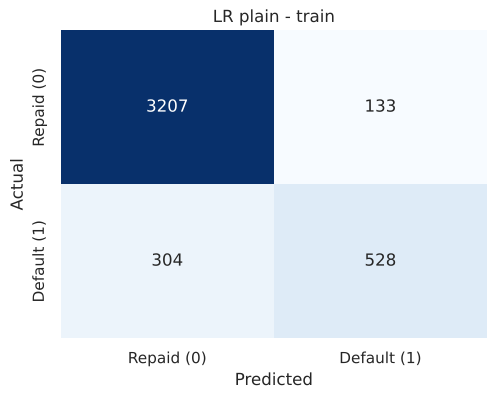

Test performance - Logistic Regression (plain)
              precision    recall  f1-score   support

           0      0.898     0.959     0.928      1431
           1      0.774     0.566     0.654       357

    accuracy                          0.880      1788
   macro avg      0.836     0.762     0.791      1788
weighted avg      0.874     0.880     0.873      1788



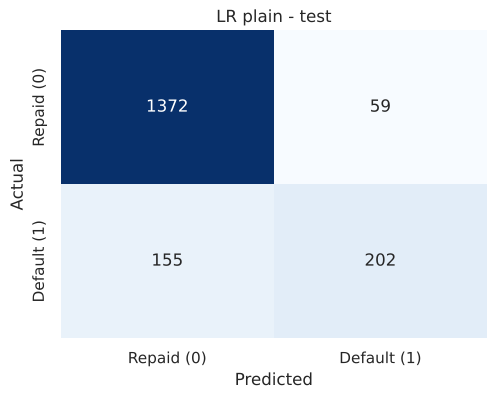

In [45]:
# 1. Plain logistic regression
lr_plain = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
lr_plain.fit(X_train_lr_s, y_train_lr)

print("Train performance - Logistic Regression (plain)")
metrics_score(y_train_lr, lr_plain.predict(X_train_lr_s), title="LR plain - train")
print("Test performance - Logistic Regression (plain)")
metrics_score(y_test_lr, lr_plain.predict(X_test_lr_s), title="LR plain - test")
results.append(model_scores(lr_plain, X_train_lr_s, y_train_lr, X_test_lr_s, y_test_lr, "Logistic Regression (plain)"))

Best C: {'C': 1} | best CV recall: 0.814
 param_C  CV recall
   0.010      0.796
   0.100      0.804
   1.000      0.814
  10.000      0.811

Train performance - Logistic Regression (balanced, tuned C)
              precision    recall  f1-score   support

           0      0.951     0.863     0.905      3340
           1      0.598     0.821     0.692       832

    accuracy                          0.854      4172
   macro avg      0.774     0.842     0.798      4172
weighted avg      0.880     0.854     0.862      4172



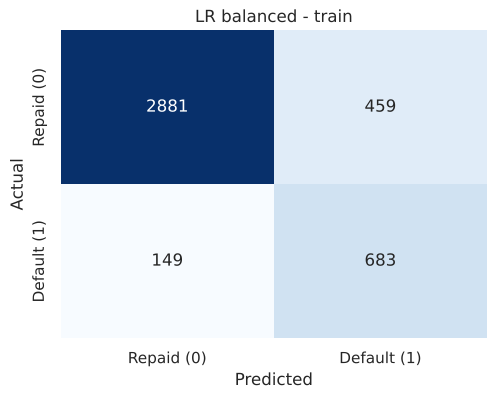

Test performance - Logistic Regression (balanced, tuned C)
              precision    recall  f1-score   support

           0      0.945     0.872     0.907      1431
           1      0.608     0.796     0.689       357

    accuracy                          0.857      1788
   macro avg      0.776     0.834     0.798      1788
weighted avg      0.878     0.857     0.864      1788



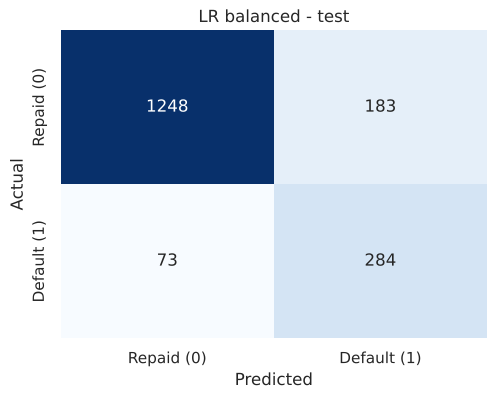

In [46]:
# 2. Logistic regression with balanced class weights, 3. with the regularisation strength tuned by grid search
lr_search = GridSearchCV(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
                         {"C": [0.01, 0.1, 1, 10]}, scoring="recall", cv=cv5, n_jobs=-1)
lr_search.fit(X_train_lr_s, y_train_lr)
print("Best C:", lr_search.best_params_, f"| best CV recall: {lr_search.best_score_:.3f}")
print(pd.DataFrame(lr_search.cv_results_)[["param_C", "mean_test_score"]].rename(columns={"mean_test_score": "CV recall"}).round(3).to_string(index=False))
lr_bal = lr_search.best_estimator_

print("\nTrain performance - Logistic Regression (balanced, tuned C)")
metrics_score(y_train_lr, lr_bal.predict(X_train_lr_s), title="LR balanced - train")
print("Test performance - Logistic Regression (balanced, tuned C)")
metrics_score(y_test_lr, lr_bal.predict(X_test_lr_s), title="LR balanced - test")
results.append(model_scores(lr_bal, X_train_lr_s, y_train_lr, X_test_lr_s, y_test_lr, "Logistic Regression (balanced)"))

**Observations - Logistic Regression:**
- The plain model is accurate overall (about 88% on test) but catches only about **57% of defaulters** on the test set: it is biased towards predicting "repaid" because that is the majority class.
- Balancing the class weights raises test recall to about **80%** while precision falls to about 61% and accuracy to about 86%. In business terms the balanced model catches roughly 23 more defaulters out of every 100, at the cost of rejecting more good customers.
- Regularisation strength makes little difference (cross-validated recall is within two points across `C` from 0.01 to 10), so the linear model is not limited by its regularisation but by its functional form.
- Train and test scores are close, so the linear model is **not over-fitting**; its limitation is that a straight line on the raw inputs cannot capture the threshold effects seen in the EDA (binned or interaction features would help, and are listed as further work).
- ROC-AUC of about 0.91 shows the model ranks applicants well even though a fixed 0.5 cut-off is not ideal.

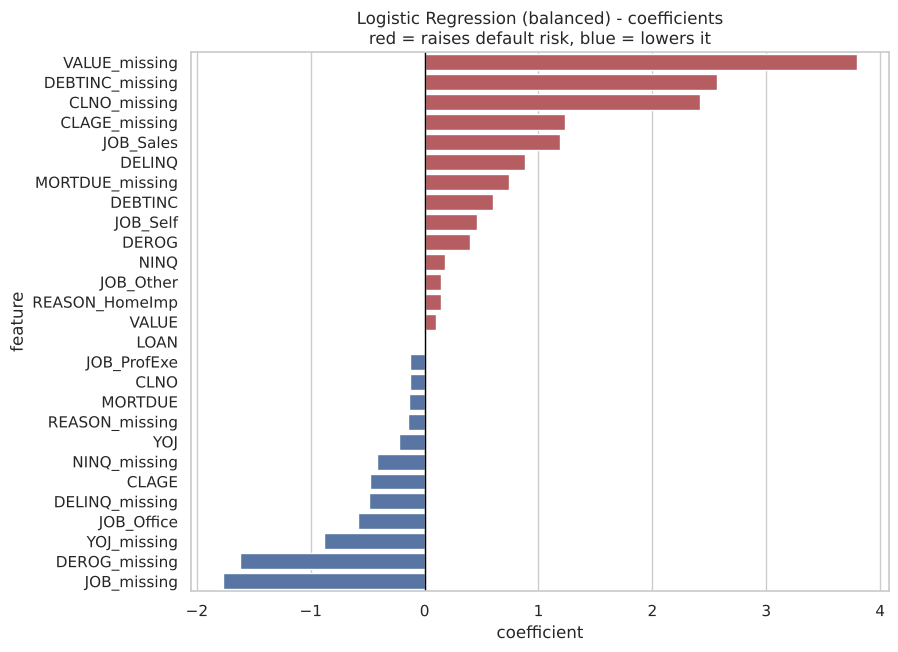

,feature,coefficient,odds_ratio,unit
0,VALUE_missing,3.797,44.551,flag 0 -> 1
1,DEBTINC_missing,2.571,13.074,flag 0 -> 1
2,CLNO_missing,2.417,11.214,flag 0 -> 1
3,CLAGE_missing,1.237,3.445,flag 0 -> 1
4,JOB_Sales,1.193,3.296,flag 0 -> 1
5,DELINQ,0.884,2.422,per 1 standard deviation
6,MORTDUE_missing,0.745,2.106,flag 0 -> 1
7,DEBTINC,0.600,1.821,per 1 standard deviation
8,JOB_Self,0.462,1.587,flag 0 -> 1
9,DEROG,0.401,1.494,per 1 standard deviation


In [47]:
# Coefficients and odds ratios of the balanced logistic regression.
# Continuous inputs are standardised, so their coefficients are per one standard deviation;
# flags and dummies are 0/1, so their coefficients are the effect of the flag switching on.
coef = pd.DataFrame({"feature": X_train_lr_s.columns, "coefficient": lr_bal.coef_[0]})
coef["odds_ratio"] = np.exp(coef["coefficient"])
coef["unit"] = ["per 1 standard deviation" if f in num_cols else "flag 0 -> 1" for f in coef["feature"]]
coef = coef.sort_values("coefficient", ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, 7))
colors = ["#C44E52" if c > 0 else "#4C72B0" for c in coef["coefficient"]]
sns.barplot(data=coef, x="coefficient", y="feature", palette=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Logistic Regression (balanced) - coefficients\nred = raises default risk, blue = lowers it")
plt.show()
coef

**Insights - what the linear model says drives default:**

- **Risk-increasing (positive coefficients):** the missing-value flags dominate. An application with **no property valuation has odds of default about 45 times higher** and one with **no debt-to-income ratio about 13 times higher**, all else equal; a missing count of credit lines also raises the odds sharply (these flags are 0/1, so the odds ratios are the full effect of the flag). Among the continuous inputs `DELINQ` (odds ratio about 2.4 per standard deviation) and `DEBTINC` (about 1.8) matter most, followed by `DEROG` and `NINQ`; the `JOB_Sales` indicator roughly triples the odds relative to a manager.
- **Risk-decreasing (negative coefficients):** `CLAGE` (longer credit history, odds ratio about 0.6 per standard deviation), `YOJ` (job tenure), `JOB_Office`, and the `DEROG`, `JOB`, `YOJ` and `DELINQ` missing flags (the groups for which these fields were blank defaulted less often in the EDA).
- `LOAN` has almost no linear effect once the other variables are included: its relationship with default is non-linear (small loans are riskier, large loans are not), which a straight line cannot represent.
- `MORTDUE` and `VALUE` have opposite signs, the classic symptom of their 0.88 correlation; individually these two coefficients should not be over-interpreted.
- The signs agree with the EDA and with lending common sense, which gives confidence that the model is learning real risk rather than noise.

#### Can a different threshold improve the linear model?

The default cut-off is 0.5. For an imbalanced problem the best operating point is usually lower. The precision-recall trade-off below shows what the bank gains and loses by moving the threshold.

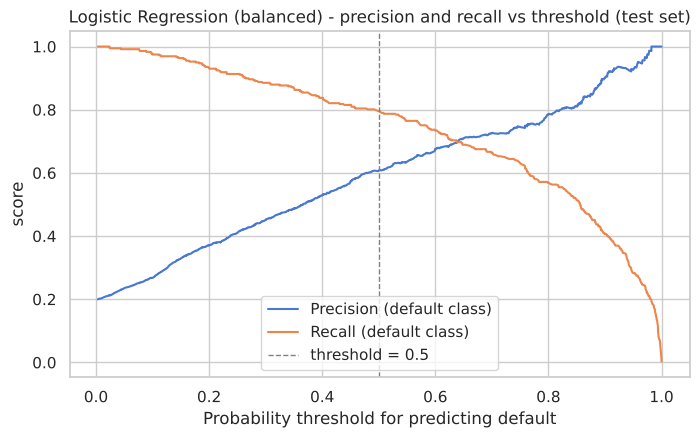

,threshold,recall,precision,f1,accuracy
0,0.300,0.885,0.451,0.597,0.762
1,0.400,0.838,0.529,0.649,0.819
2,0.500,0.796,0.608,0.689,0.857
3,0.600,0.734,0.675,0.703,0.876


In [48]:
proba_lr = lr_bal.predict_proba(X_test_lr_s)[:, 1]
prec, rec, thr = precision_recall_curve(y_test_lr, proba_lr)

plt.figure(figsize=(8, 4.5))
plt.plot(thr, prec[:-1], label="Precision (default class)")
plt.plot(thr, rec[:-1], label="Recall (default class)")
plt.axvline(0.5, color="grey", linestyle="--", linewidth=1, label="threshold = 0.5")
plt.xlabel("Probability threshold for predicting default"); plt.ylabel("score")
plt.title("Logistic Regression (balanced) - precision and recall vs threshold (test set)")
plt.legend(); plt.show()

# Metrics at a few candidate thresholds (illustration only; the threshold of the final model is chosen on training data below)
rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    p = (proba_lr > t).astype(int)
    rows.append({"threshold": t, "recall": recall_score(y_test_lr, p),
                 "precision": precision_score(y_test_lr, p), "f1": f1_score(y_test_lr, p),
                 "accuracy": accuracy_score(y_test_lr, p)})
pd.DataFrame(rows)

**Observations:**
- Lowering the threshold to 0.4 lifts recall to about 83% but precision drops to about 53%; raising it to 0.6 does the reverse (about 74% recall, 67% precision). F1 is highest around 0.5-0.6, so the balanced model at 0.5 is already close to its best balance.
- The threshold is a **business lever**, not a technical constant: the bank's risk appetite decides where to sit on this curve. For the final model it is chosen formally, on training data, in the model-selection section.

### Decision Tree

A decision tree learns a sequence of yes/no questions ("Is DEBTINC above 43.7%?") that split the applicants into increasingly pure groups. It captures the threshold effects seen in the EDA directly and produces rules that can be read out to an applicant or a regulator.

Tree models are trained on the **untreated data** (`X_train`, `X_test`): outliers do not distort tree splits, and keeping the real values preserves information such as "DEBTINC above 50% almost always defaults".

We start with a fully grown tree to establish a baseline, then add class weights, then prune with grid search.

Train performance - Decision Tree (default)
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      3340
           1      1.000     1.000     1.000       832

    accuracy                          1.000      4172
   macro avg      1.000     1.000     1.000      4172
weighted avg      1.000     1.000     1.000      4172



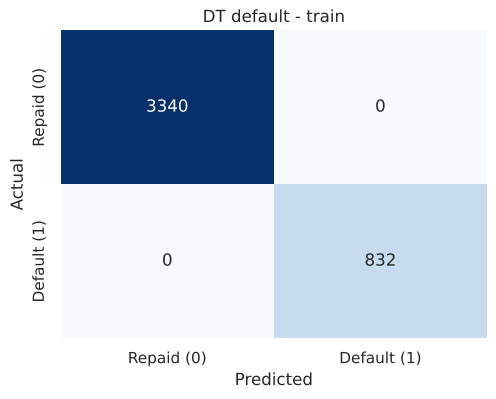

Test performance - Decision Tree (default)
              precision    recall  f1-score   support

           0      0.922     0.929     0.925      1431
           1      0.706     0.686     0.696       357

    accuracy                          0.880      1788
   macro avg      0.814     0.807     0.811      1788
weighted avg      0.879     0.880     0.880      1788



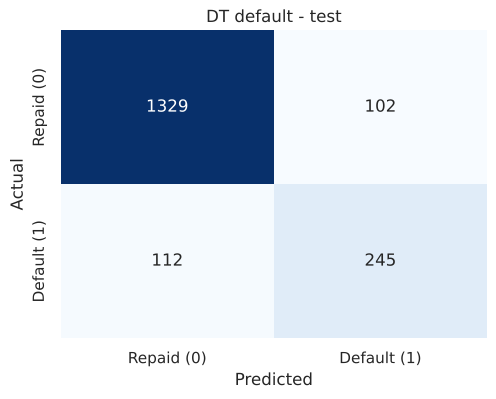

Tree depth: 28 | number of leaves: 366


In [49]:
# Baseline decision tree (fully grown)
dt_base = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_base.fit(X_train, y_train)

print("Train performance - Decision Tree (default)")
metrics_score(y_train, dt_base.predict(X_train), title="DT default - train")
print("Test performance - Decision Tree (default)")
metrics_score(y_test, dt_base.predict(X_test), title="DT default - test")
results.append(model_scores(dt_base, X_train, y_train, X_test, y_test, "Decision Tree (default)"))
print("Tree depth:", dt_base.get_depth(), "| number of leaves:", dt_base.get_n_leaves())

**Observations - default Decision Tree:**
- The fully grown tree is a textbook case of **over-fitting**: 100% recall, precision and accuracy on the training data, but only about **69% recall** and 71% precision on the test set. It has memorised the training applicants (dozens of levels deep, hundreds of leaves) instead of learning general rules.
- Even so, its test recall is already higher than the plain logistic regression, confirming that non-linear splits help on this data.

Train performance - Decision Tree (class weights 0.2/0.8)
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      3340
           1      1.000     1.000     1.000       832

    accuracy                          1.000      4172
   macro avg      1.000     1.000     1.000      4172
weighted avg      1.000     1.000     1.000      4172



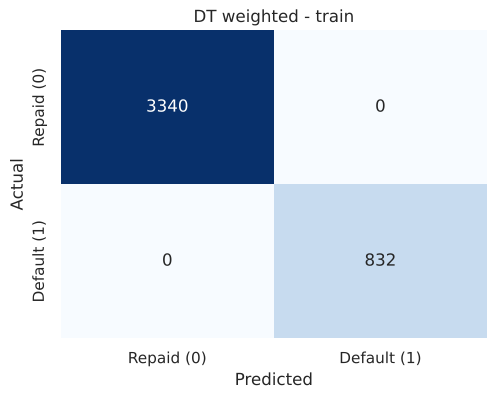

Test performance - Decision Tree (class weights 0.2/0.8)
              precision    recall  f1-score   support

           0      0.908     0.940     0.923      1431
           1      0.719     0.616     0.664       357

    accuracy                          0.875      1788
   macro avg      0.813     0.778     0.794      1788
weighted avg      0.870     0.875     0.872      1788



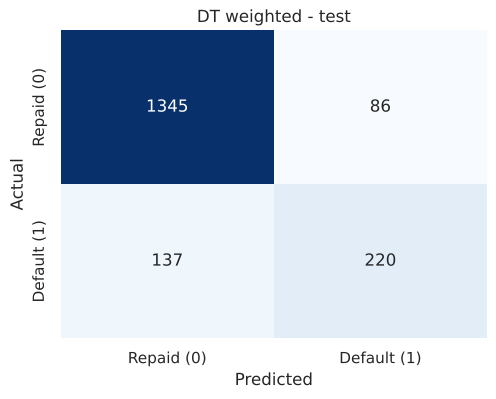

In [50]:
# Decision tree with class weights favouring the defaulter class
dt_cw = DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight={0: 0.2, 1: 0.8})
dt_cw.fit(X_train, y_train)

print("Train performance - Decision Tree (class weights 0.2/0.8)")
metrics_score(y_train, dt_cw.predict(X_train), title="DT weighted - train")
print("Test performance - Decision Tree (class weights 0.2/0.8)")
metrics_score(y_test, dt_cw.predict(X_test), title="DT weighted - test")
results.append(model_scores(dt_cw, X_train, y_train, X_test, y_test, "Decision Tree (class weights)"))

**Observations:**
- Adding class weights to an un-pruned tree does **not** help: test recall is about 62%, no better than the baseline. The weights change the weighted impurity and therefore which splits are chosen (this is a different tree), but they cannot change the fact that a fully grown tree fits every training applicant perfectly, so the test predictions remain those of an over-fitted tree.
- Class weights only pay off once the tree is constrained (pruned), which is what the grid search does next.

### **Decision Tree - Hyperparameter Tuning**

* Hyperparameter tuning is tricky in the sense that **there is no direct way to calculate how a change in the hyperparameter value will reduce the loss of your model**, so we usually resort to experimentation. We'll use Grid search to perform hyperparameter tuning.
* **Grid search is a tuning technique that attempts to compute the optimum values of hyperparameters.**
* **It is an exhaustive search** that is performed on the specific parameter values of a model.
* The parameters of the estimator/model used to apply these methods are **optimized by cross-validated grid-search** over a parameter grid.

**Criterion {"gini", "entropy"}**

The function to measure the quality of a split. Supported criteria are "gini" for the Gini impurity and "entropy" for the information gain.

**max_depth**

The maximum depth of the tree. If None, then nodes are expanded until all leaves are pure or until all leaves contain less than min_samples_split samples.

**min_samples_leaf**

The minimum number of samples is required to be at a leaf node. A split point at any depth will only be considered if it leaves at least min_samples_leaf training samples in each of the left and right branches. This may have the effect of smoothing the model, especially in regression.

You can learn about more Hyperpapameters on this link and try to tune them.

https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

We search over depth, minimum leaf size, split criterion and class weights, using **5-fold stratified cross-validation on the training set with Recall as the scoring metric**. Because class weights are in the grid, recall-scoring will favour the heavier minority weighting; the precision cost of that choice is reported alongside.

In [51]:
dt_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 5, 10, 20, 50],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced", {0: 0.2, 1: 0.8}],
}

dt_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), dt_grid,
                         scoring="recall", cv=cv5, n_jobs=-1)
dt_search.fit(X_train, y_train)

print("Best parameters :", dt_search.best_params_)
print(f"Best CV recall  : {dt_search.best_score_:.3f}")
dt_tuned = dt_search.best_estimator_

Best parameters : {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 20}
Best CV recall  : 0.826


Train performance - Decision Tree (tuned)
              precision    recall  f1-score   support

           0      0.977     0.826     0.895      3340
           1      0.569     0.921     0.703       832

    accuracy                          0.845      4172
   macro avg      0.773     0.874     0.799      4172
weighted avg      0.895     0.845     0.857      4172



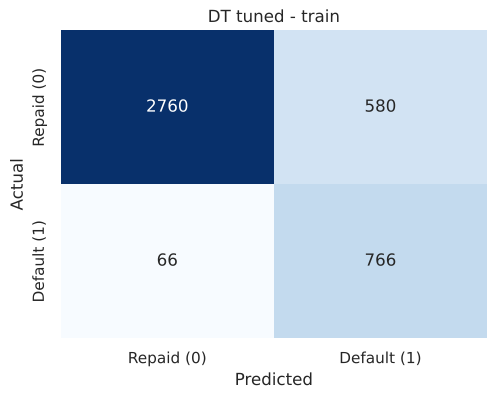

Test performance - Decision Tree (tuned)
              precision    recall  f1-score   support

           0      0.948     0.819     0.879      1431
           1      0.531     0.821     0.645       357

    accuracy                          0.819      1788
   macro avg      0.740     0.820     0.762      1788
weighted avg      0.865     0.819     0.832      1788



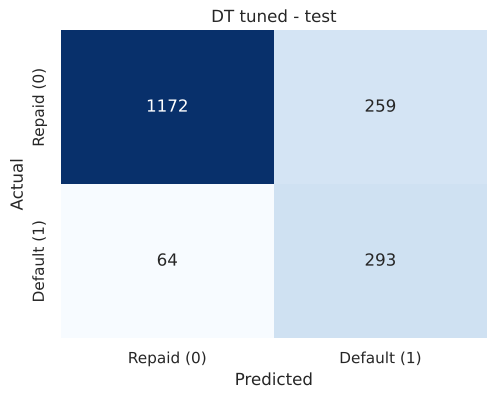

Tree depth: 14 | number of leaves: 106


In [52]:
print("Train performance - Decision Tree (tuned)")
metrics_score(y_train, dt_tuned.predict(X_train), title="DT tuned - train")
print("Test performance - Decision Tree (tuned)")
metrics_score(y_test, dt_tuned.predict(X_test), title="DT tuned - test")
results.append(model_scores(dt_tuned, X_train, y_train, X_test, y_test, "Decision Tree (tuned)"))
print("Tree depth:", dt_tuned.get_depth(), "| number of leaves:", dt_tuned.get_n_leaves())

**Observations - tuned Decision Tree:**
- Pruning (a minimum of 20 applicants per leaf, which cuts the tree from several hundred leaves to about 100) combined with balanced class weights lifts **test recall to about 82%**, the highest of the single-model approaches. The train-test gap narrows from about 30 points to about 10 (92% vs 82%), so over-fitting is much reduced though not gone.
- The price is precision: only about 53% of the applicants the tree rejects would actually have defaulted, and overall accuracy falls to about 82%. The tree is deliberately cautious - it flags anyone who looks even moderately risky.
- This is the recall-precision trade-off in action. Whether 53% precision is acceptable depends on how much good business the bank is willing to turn away; the ensembles below improve this balance.

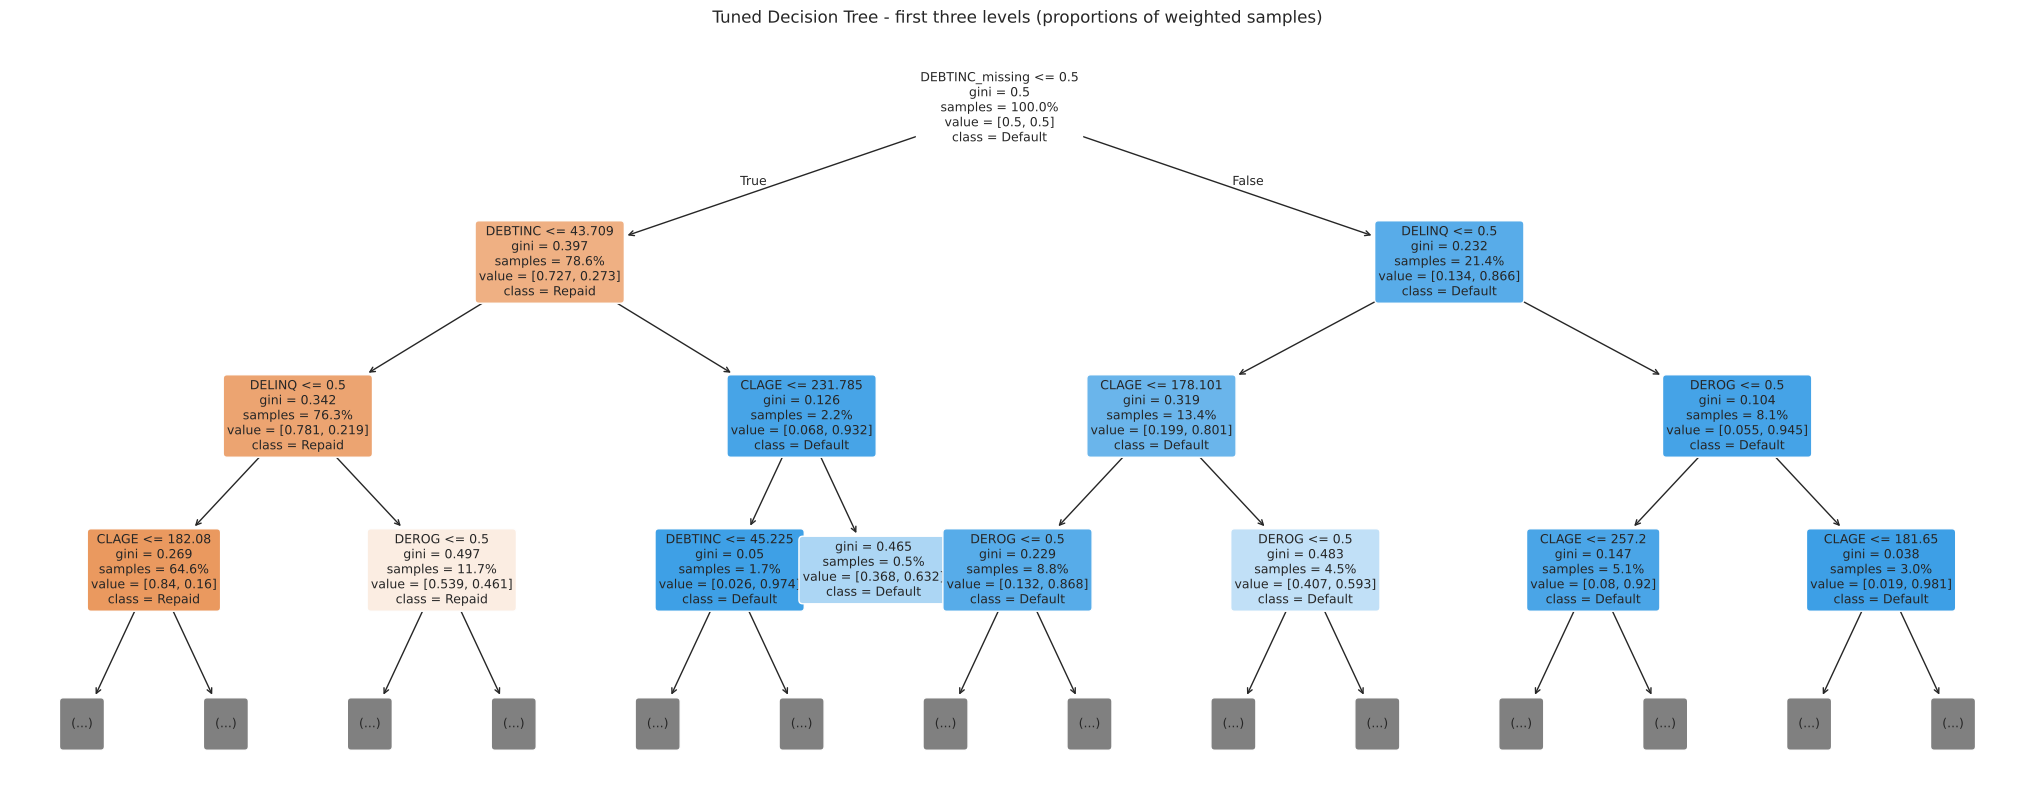

In [53]:
# Visualise the top levels of the tuned tree (the full tree is deeper; the first 3 levels carry the main rules)
plt.figure(figsize=(26, 10))
plot_tree(dt_tuned, feature_names=X_train.columns, class_names=["Repaid", "Default"],
          filled=True, rounded=True, max_depth=3, fontsize=9, proportion=True)
plt.title("Tuned Decision Tree - first three levels (proportions of weighted samples)")
plt.show()

In [54]:
# Text version of the decision rules (first three levels). Note: the tree was fitted with balanced class weights,
# so a leaf labelled 'class: 1' means the weighted majority is 'default', i.e. a raw default rate above roughly 20%,
# not a near-certain default. The observed default rates of the main rules are computed next.
print(export_text(dt_tuned, feature_names=list(X_train.columns), max_depth=3, show_weights=False))

|--- DEBTINC_missing <= 0.50
|   |--- DEBTINC <= 43.71
|   |   |--- DELINQ <= 0.50
|   |   |   |--- CLAGE <= 182.08
|   |   |   |   |--- truncated branch of depth 11
|   |   |   |--- CLAGE >  182.08
|   |   |   |   |--- truncated branch of depth 10
|   |   |--- DELINQ >  0.50
|   |   |   |--- DEROG <= 0.50
|   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- DEROG >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |--- DEBTINC >  43.71
|   |   |--- CLAGE <= 231.79
|   |   |   |--- DEBTINC <= 45.23
|   |   |   |   |--- class: 1
|   |   |   |--- DEBTINC >  45.23
|   |   |   |   |--- class: 1
|   |   |--- CLAGE >  231.79
|   |   |   |--- class: 1
|--- DEBTINC_missing >  0.50
|   |--- DELINQ <= 0.50
|   |   |--- CLAGE <= 178.10
|   |   |   |--- DEROG <= 0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- DEROG >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- CLAGE >  178.10
|   |   |   |--- DEROG <= 0.50
|   |   |   |   |--- tr

In [55]:
# Observed default rate (training rows) of the groups defined by the tree's first splits
tr = data.loc[train_idx]
root_split = dt_tuned.tree_.threshold[dt_tuned.tree_.children_left[0]]   # DEBTINC threshold under 'DEBTINC_missing <= 0.5'
groups = {
    "Debt-to-income ratio missing": tr["DEBTINC_missing"] == 1,
    f"Ratio recorded and above {root_split:.1f}%": (tr["DEBTINC_missing"] == 0) & (tr["DEBTINC"] > root_split),
    f"Ratio recorded, at most {root_split:.1f}%, 1+ delinquent lines": (tr["DEBTINC_missing"] == 0) & (tr["DEBTINC"] <= root_split) & (tr["DELINQ"] >= 1),
    f"Ratio recorded, at most {root_split:.1f}%, no delinquent lines": (tr["DEBTINC_missing"] == 0) & (tr["DEBTINC"] <= root_split) & (tr["DELINQ"] == 0),
}
pd.DataFrame({"applicants": {k: int(v.sum()) for k, v in groups.items()},
              "default_rate_%": {k: round(tr.loc[v, "BAD"].astype(int).mean() * 100, 1) for k, v in groups.items()}})

,applicants,default_rate_%
Debt-to-income ratio missing,894,61.700
Ratio recorded and above 43.7%,93,77.400
"Ratio recorded, at most 43.7%, 1+ delinquent lines",490,17.600
"Ratio recorded, at most 43.7%, no delinquent lines",2695,4.500


**Business rules deduced from the tree:**

Reading the top of the tree, with the observed default rates of each group, gives the bank plain-language rules it can defend in front of an applicant or a regulator:

1. **Is the debt-to-income ratio missing?** If yes, the applicant is in a high-risk group: about 62% of these applicants defaulted. Unverified income should trigger either a rejection or a mandatory income-verification step.
2. **If the ratio is recorded, is it above about 44%?** If yes, roughly three out of four defaulted (and above 45% the EDA showed 87% to 100%): decline.
3. **Below that ratio, how many delinquent credit lines does the applicant have?** With none, only about 4-5% default (the safest group in the book); with one or more the rate is about four times higher and the tree asks further questions.
4. **Among the remaining applicants, how long is the credit history (CLAGE) and are there derogatory reports (DEROG)?** Short histories (under about 15 years) with any derogatory report are risky; long clean histories are safe.
5. **In the "ratio missing" branch the same questions are asked again** (delinquencies, derogatory reports, credit-history length, loan size), and almost every path that combines a missing ratio with any delinquency or derogatory report ends in "default".

These rules match the EDA findings exactly, which is reassuring: the model is formalising the patterns in the data rather than inventing new ones.

### Bagging (Bootstrap Aggregating): from one tree to many

A single decision tree has **high variance**: small changes in the training data produce a different tree, which is why the fully grown tree scored 100% on training data and far less on test data. **Bagging** trains many trees, each on a *bootstrap sample* (a random sample of the training applicants drawn with replacement), and combines their votes. Averaging many over-fitted trees cancels out their individual errors, which lowers variance without raising bias.

A Random Forest is bagging plus one more idea (a random subset of features at every split), so building a plain bagged ensemble first shows how much of the improvement comes from bagging alone.

Train performance - Bagging (200 trees)
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      3340
           1      1.000     1.000     1.000       832

    accuracy                          1.000      4172
   macro avg      1.000     1.000     1.000      4172
weighted avg      1.000     1.000     1.000      4172



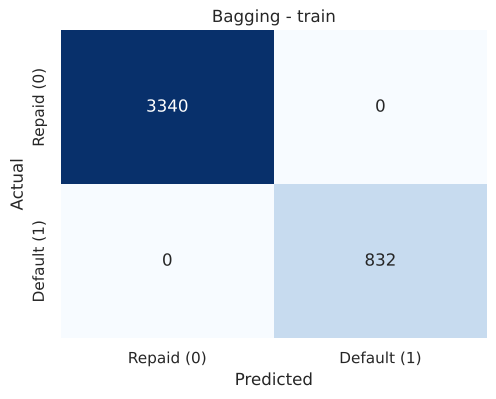

Test performance - Bagging (200 trees)


              precision    recall  f1-score   support

           0      0.924     0.964     0.944      1431
           1      0.827     0.683     0.748       357

    accuracy                          0.908      1788
   macro avg      0.876     0.824     0.846      1788
weighted avg      0.905     0.908     0.905      1788



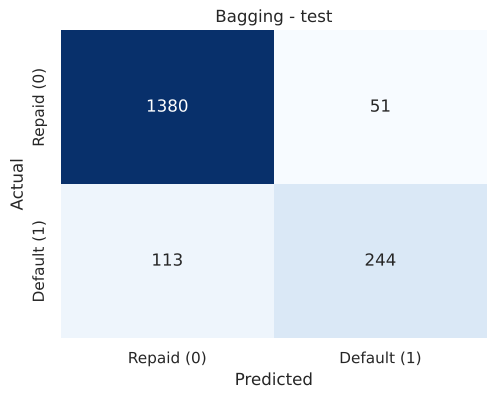

In [56]:
from sklearn.ensemble import BaggingClassifier

# Bagging of 200 fully grown decision trees
bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
bag.fit(X_train, y_train)

print("Train performance - Bagging (200 trees)")
metrics_score(y_train, bag.predict(X_train), title="Bagging - train")
print("Test performance - Bagging (200 trees)")
metrics_score(y_test, bag.predict(X_test), title="Bagging - test")
results.append(model_scores(bag, X_train, y_train, X_test, y_test, "Bagging (200 trees)"))

In [57]:
# Does weighting the base trees towards the defaulter class help a bagged ensemble?
bag_cw = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight={0: 0.2, 1: 0.8}),
                           n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
bag_cw.fit(X_train, y_train)
results.append(model_scores(bag_cw, X_train, y_train, X_test, y_test, "Bagging (class-weighted trees)"))
pd.concat(results[-2:], ignore_index=True).set_index("Model").round(3)

,Train Recall,Test Recall,Train Precision,Test Precision,Train F1,Test F1,Train Accuracy,Test Accuracy,Test ROC-AUC
Model,,,,,,,,,
Bagging (200 trees),1.000,0.683,1.000,0.827,1.000,0.748,1.000,0.908,0.945
Bagging (class-weighted trees),1.000,0.597,1.000,0.810,1.000,0.687,1.000,0.891,0.946


**Observations - Bagging:**
- Averaging 200 trees lifts **test precision from 71% (single tree) to about 83% and ROC-AUC from 0.81 to about 0.95** at the same recall (about 68%). That is the variance reduction bagging promises: the ensemble is right far more often when it flags a defaulter, and it ranks applicants by risk almost as well as the forest will.
- Train recall is still 100%: bagging limits the *damage* of over-fitting on unseen data, it does not stop each tree from memorising its sample.
- Weighting the base trees towards the defaulter class does **not** raise recall (it falls to about 60%): as with the single tree, the weights change which splits each fully grown tree makes but not the fact that it fits its bootstrap sample perfectly. Class weights become useful once the trees are also constrained, which is what the random forest tuning below does.
- A bagged ensemble still misses about a third of defaulters. The random forest adds feature sub-sampling, which de-correlates the trees and should improve both ranking and, combined with class weights, recall.

### **Building a Random Forest Classifier**

**Random Forest is a bagging algorithm where the base models are Decision Trees.** Samples are taken from the training data and on each sample a decision tree makes a prediction.

**The results from all the decision trees are combined together and the final prediction is made using voting or averaging.**

Because each tree sees a different bootstrap sample and a random subset of features at each split, the individual over-fitted trees average out, which usually gives a large improvement in test performance over a single tree while keeping the ability to model thresholds. The cost is interpretability: a forest of hundreds of trees cannot be read as a rule list, so we will rely on **feature importances** and, for the final model, a **surrogate decision tree** to explain it.

Train performance - Random Forest (default)
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      3340
           1      1.000     1.000     1.000       832

    accuracy                          1.000      4172
   macro avg      1.000     1.000     1.000      4172
weighted avg      1.000     1.000     1.000      4172



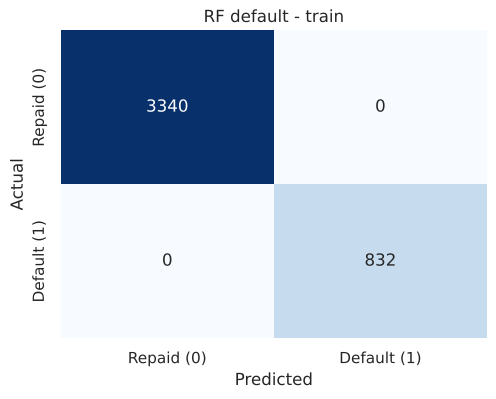

Test performance - Random Forest (default)
              precision    recall  f1-score   support

           0      0.925     0.968     0.946      1431
           1      0.842     0.686     0.756       357

    accuracy                          0.912      1788
   macro avg      0.884     0.827     0.851      1788
weighted avg      0.909     0.912     0.908      1788



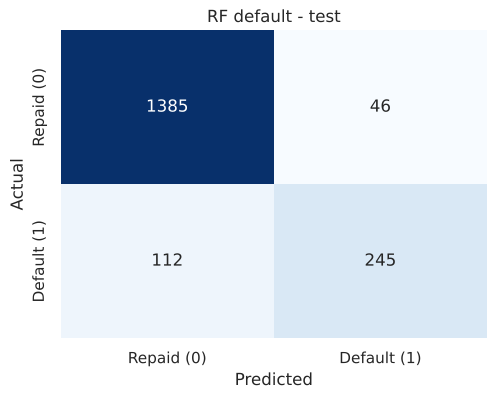

In [58]:
# Baseline random forest
rf_base = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train, y_train)

print("Train performance - Random Forest (default)")
metrics_score(y_train, rf_base.predict(X_train), title="RF default - train")
print("Test performance - Random Forest (default)")
metrics_score(y_test, rf_base.predict(X_test), title="RF default - test")
results.append(model_scores(rf_base, X_train, y_train, X_test, y_test, "Random Forest (default)"))

**Observations - default Random Forest:**
- Like the single tree, the forest fits the training data perfectly, but on the test set it is much stronger: about **69% recall with 84% precision**, 91% accuracy and a ROC-AUC of about 0.96 (the best ranking ability of all the models).
- The forest is conservative about calling someone a defaulter: when it does, it is right 84% of the time, but it still misses about a third of the defaulters. Class weights should shift that balance towards recall.

### **Build a Random Forest model with Class Weights**

Train performance - Random Forest (class weights 0.2/0.8)
              precision    recall  f1-score   support

           0      1.000     0.998     0.999      3340
           1      0.993     1.000     0.996       832

    accuracy                          0.999      4172
   macro avg      0.996     0.999     0.998      4172
weighted avg      0.999     0.999     0.999      4172



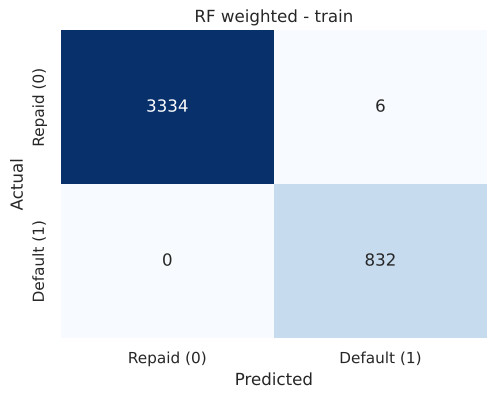

Test performance - Random Forest (class weights 0.2/0.8)


              precision    recall  f1-score   support

           0      0.943     0.942     0.943      1431
           1      0.769     0.773     0.771       357

    accuracy                          0.908      1788
   macro avg      0.856     0.858     0.857      1788
weighted avg      0.908     0.908     0.908      1788



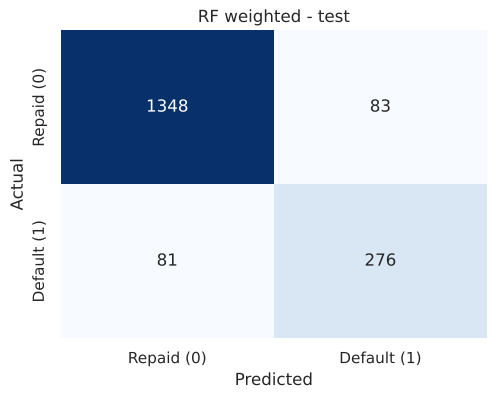

In [59]:
rf_cw = RandomForestClassifier(n_estimators=200, class_weight={0: 0.2, 1: 0.8},
                               random_state=RANDOM_STATE, n_jobs=-1)
rf_cw.fit(X_train, y_train)

print("Train performance - Random Forest (class weights 0.2/0.8)")
metrics_score(y_train, rf_cw.predict(X_train), title="RF weighted - train")
print("Test performance - Random Forest (class weights 0.2/0.8)")
metrics_score(y_test, rf_cw.predict(X_test), title="RF weighted - test")
results.append(model_scores(rf_cw, X_train, y_train, X_test, y_test, "Random Forest (class weights)"))

**Observations - weighted Random Forest:**
- Class weights lift **test recall to about 77%** while precision stays near 77% and accuracy near 91%. Unlike the single tree, the forest benefits from class weights because each bootstrap tree is different and the weights change how the ensemble votes.
- This is the best balance of recall and precision so far: the forest catches almost as many defaulters as the balanced logistic regression (77% vs 80%) with far higher precision (77% vs 61%), so it declines far fewer good customers.
- Train scores are still near-perfect, so there is residual over-fitting of the training labels; whether that hurts on unseen applicants is judged below with out-of-fold cross-validation rather than training scores.

### **Random Forest Classifier Hyperparameter Tuning**

We search over the number of trees, maximum depth, minimum leaf size, the number of features considered per split and the class weights, again with **stratified 3-fold cross-validation on the training data and Recall as the scoring metric**. (3 folds instead of 5 keep the run time reasonable for the larger forest grid.)

In [60]:
rf_grid = {
    "n_estimators": [150, 300],
    "max_depth": [6, 10, None],
    "min_samples_leaf": [1, 5, 10],
    "max_features": ["sqrt", 0.5],
    "class_weight": ["balanced", {0: 0.2, 1: 0.8}],
}

rf_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), rf_grid,
                         scoring="recall", cv=cv3, n_jobs=-1)
rf_search.fit(X_train, y_train)

print("Best parameters :", rf_search.best_params_)
print(f"Best CV recall  : {rf_search.best_score_:.3f}")
rf_tuned = rf_search.best_estimator_

Best parameters : {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 300}
Best CV recall  : 0.811


Train performance - Random Forest (tuned for recall)
              precision    recall  f1-score   support

           0      0.978     0.901     0.938      3340
           1      0.699     0.918     0.794       832

    accuracy                          0.905      4172
   macro avg      0.838     0.910     0.866      4172
weighted avg      0.922     0.905     0.909      4172



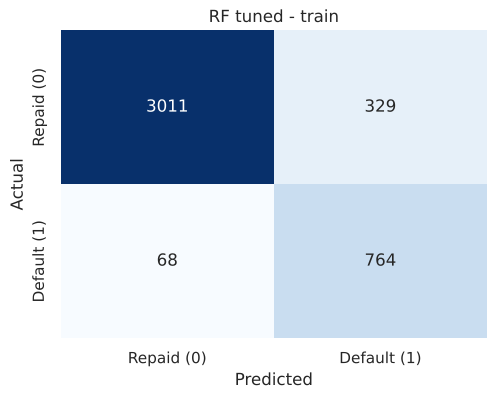

Test performance - Random Forest (tuned for recall)
              precision    recall  f1-score   support

           0      0.945     0.897     0.920      1431
           1      0.656     0.790     0.717       357

    accuracy                          0.875      1788
   macro avg      0.800     0.843     0.818      1788
weighted avg      0.887     0.875     0.879      1788



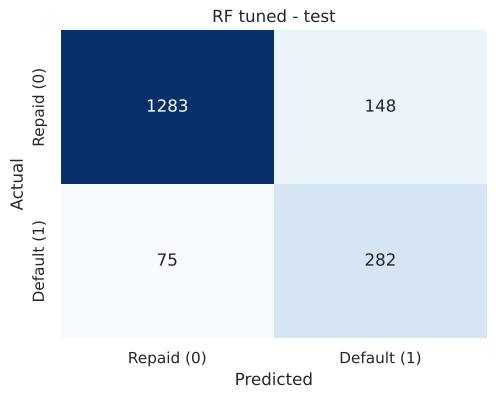

In [61]:
print("Train performance - Random Forest (tuned for recall)")
metrics_score(y_train, rf_tuned.predict(X_train), title="RF tuned - train")
print("Test performance - Random Forest (tuned for recall)")
metrics_score(y_test, rf_tuned.predict(X_test), title="RF tuned - test")
results.append(model_scores(rf_tuned, X_train, y_train, X_test, y_test, "Random Forest (tuned, recall)"))

**Observations - recall-tuned Random Forest:**
- Optimising purely for recall pushes the grid towards larger leaves (10 applicants minimum) and balanced weights. Test recall lands at about **79%**, close to the weighted forest, but precision drops to about 66% because the forest becomes more willing to flag borderline applicants.
- The train-test gap shrinks (train recall is no longer 100%), so the tuned forest memorises less, even though its headline test numbers are no better.
- Recall-only tuning illustrates the limitation of a single-metric search on an imbalanced problem: beyond a point, extra recall is bought with a lot of precision. This is why the final model is chosen on expected cost, not on recall alone.

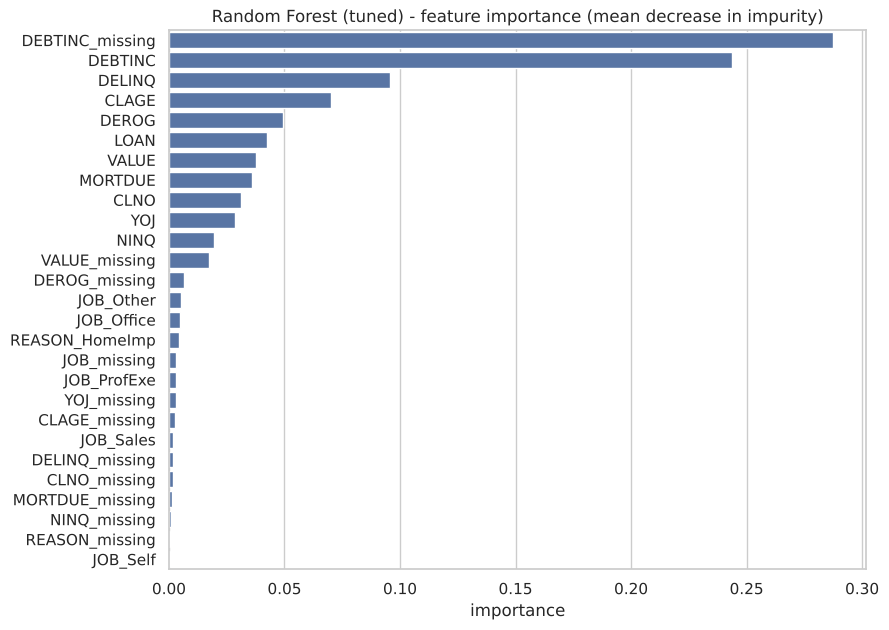

,importance
DEBTINC_missing,0.287
DEBTINC,0.244
DELINQ,0.096
CLAGE,0.070
DEROG,0.049
LOAN,0.042
VALUE,0.038
MORTDUE,0.036
CLNO,0.031
YOJ,0.028


In [62]:
# Feature importance of the recall-tuned random forest, used to test a leaner feature set
importances = pd.Series(rf_tuned.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
sns.barplot(x=importances.values, y=importances.index, color="#4C72B0")
plt.title("Random Forest (tuned) - feature importance (mean decrease in impurity)")
plt.xlabel("importance"); plt.ylabel("")
plt.show()
importances.round(4).to_frame("importance").head(12)

**Insights - what the forest relies on:**
- The two debt-to-income features dominate: **`DEBTINC_missing` and `DEBTINC` together account for about half of this forest's split power.** This confirms the EDA finding that affordability, and whether it could be verified, is the heart of the decision.
- Next come **`DELINQ`, `CLAGE` and `DEROG`** (past repayment behaviour and depth of credit history), then `LOAN`, `VALUE`, `MORTDUE` and `CLNO`.
- `NINQ`, `YOJ` and `VALUE_missing` contribute modestly. The `JOB` and `REASON` dummies rank at the bottom: once financial behaviour is known, occupation and loan purpose add little on their own. (Mean-decrease-in-impurity importance favours continuous variables with many split points, so it is complemented below with permutation importance for the final model.)

#### Improving the forest by removing weak variables

A best-practice check: does the model keep its performance with fewer inputs? A leaner model is cheaper to maintain, easier to explain and less prone to picking up spurious patterns. We refit the recall-tuned forest on only the features with importance above 1%, and carry this 12-feature set forward as a candidate in the final-model selection.

Keeping 12 of 27 features: ['DEBTINC_missing', 'DEBTINC', 'DELINQ', 'CLAGE', 'DEROG', 'LOAN', 'VALUE', 'MORTDUE', 'CLNO', 'YOJ', 'NINQ', 'VALUE_missing']
Dropped: ['MORTDUE_missing', 'REASON_missing', 'JOB_missing', 'YOJ_missing', 'DEROG_missing', 'DELINQ_missing', 'CLAGE_missing', 'NINQ_missing', 'CLNO_missing', 'REASON_HomeImp', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']


Test performance - Random Forest (tuned, reduced features)
              precision    recall  f1-score   support

           0      0.944     0.899     0.921      1431
           1      0.660     0.784     0.717       357

    accuracy                          0.876      1788
   macro avg      0.802     0.842     0.819      1788
weighted avg      0.887     0.876     0.880      1788



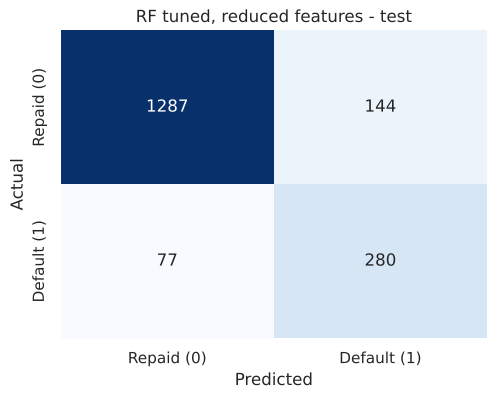

In [63]:
keep = importances[importances > 0.01].index.tolist()
dropped = [c for c in X_train.columns if c not in keep]
print(f"Keeping {len(keep)} of {X_train.shape[1]} features: {keep}")
print(f"Dropped: {dropped}")

rf_lean = RandomForestClassifier(**{k: v for k, v in rf_search.best_params_.items()},
                                 random_state=RANDOM_STATE, n_jobs=-1)
rf_lean.fit(X_train[keep], y_train)

print("Test performance - Random Forest (tuned, reduced features)")
metrics_score(y_test, rf_lean.predict(X_test[keep]), title="RF tuned, reduced features - test")
results.append(model_scores(rf_lean, X_train[keep], y_train, X_test[keep], y_test, "Random Forest (tuned, reduced features)"))

**Observations:**
- At the default 0.5 threshold, dropping the 15 low-importance columns (all occupation and loan-purpose dummies and nine of the eleven missing-value flags) changes test recall and precision by about a point. For this model the signal lives mainly in 12 variables: the ten financial attributes plus the `DEBTINC` and `VALUE` missing flags.
- Whether the leaner set is also good enough at the business-optimal threshold is tested properly in the next section, where it competes against the full feature set on expected cost.

## **Model Performance Comparison and Final Model Selection**

**1. Comparison of various techniques and their relative performance based on chosen Metric (Measure of success):**
- How do different techniques perform? Which one is performing relatively better? Is there scope to improve the performance further?

In [64]:
comparison = pd.concat(results, ignore_index=True).set_index("Model")
comparison.style.format("{:.3f}").background_gradient(subset=["Test Recall", "Test Precision", "Test F1", "Test ROC-AUC"], cmap="Blues")

,Train Recall,Test Recall,Train Precision,Test Precision,Train F1,Test F1,Train Accuracy,Test Accuracy,Test ROC-AUC
Model,,,,,,,,,
Logistic Regression (plain),0.635,0.566,0.799,0.774,0.707,0.654,0.895,0.880,0.907
Logistic Regression (balanced),0.821,0.796,0.598,0.608,0.692,0.689,0.854,0.857,0.906
Decision Tree (default),1.000,0.686,1.000,0.706,1.000,0.696,1.000,0.880,0.807
Decision Tree (class weights),1.000,0.616,1.000,0.719,1.000,0.664,1.000,0.875,0.778
Decision Tree (tuned),0.921,0.821,0.569,0.531,0.703,0.645,0.845,0.819,0.877
Bagging (200 trees),1.000,0.683,1.000,0.827,1.000,0.748,1.000,0.908,0.945
Bagging (class-weighted trees),1.000,0.597,1.000,0.810,1.000,0.687,1.000,0.891,0.946
Random Forest (default),1.000,0.686,1.000,0.842,1.000,0.756,1.000,0.912,0.963
Random Forest (class weights),1.000,0.773,0.993,0.769,0.996,0.771,0.999,0.908,0.959


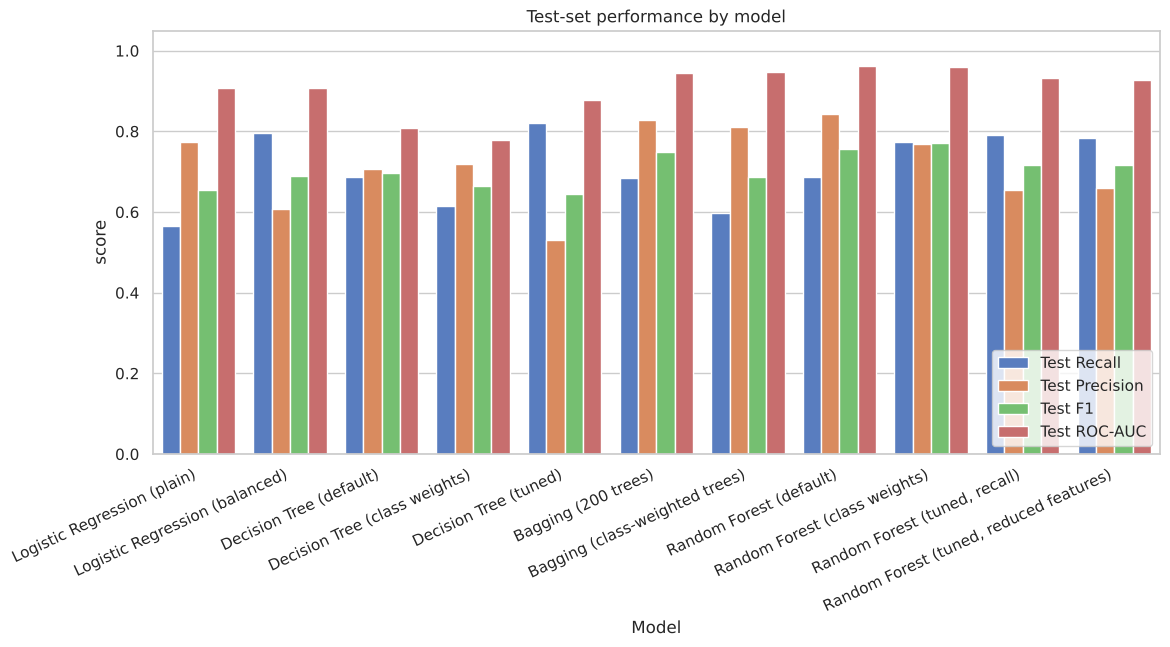

In [65]:
# Visual comparison on the test set
plot_df = comparison[["Test Recall", "Test Precision", "Test F1", "Test ROC-AUC"]].reset_index().melt(
    id_vars="Model", var_name="metric", value_name="score")
plt.figure(figsize=(13, 5.5))
ax = sns.barplot(data=plot_df, x="Model", y="score", hue="metric", palette="muted")
plt.xticks(rotation=25, ha="right"); plt.ylim(0, 1.05)
plt.title("Test-set performance by model"); plt.legend(loc="lower right")
plt.show()

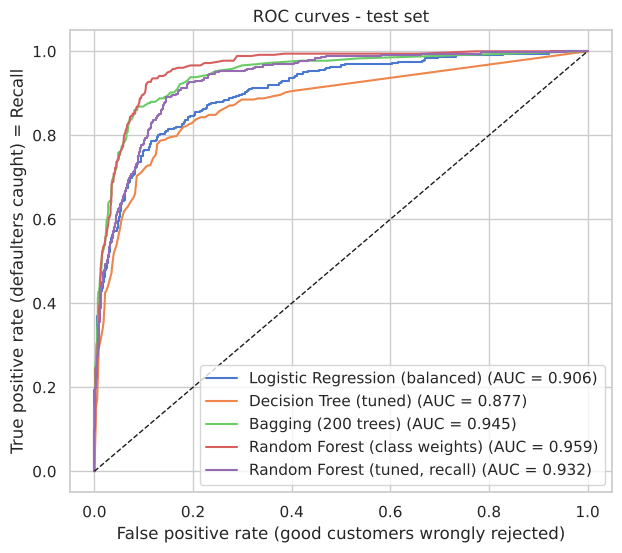

In [66]:
# ROC curves for the main candidates on the test set
plt.figure(figsize=(7, 6))
for name, model, Xt in [("Logistic Regression (balanced)", lr_bal, X_test_lr_s),
                        ("Decision Tree (tuned)", dt_tuned, X_test),
                        ("Bagging (200 trees)", bag, X_test),
                        ("Random Forest (class weights)", rf_cw, X_test),
                        ("Random Forest (tuned, recall)", rf_tuned, X_test)]:
    pr = model.predict_proba(Xt)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, pr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, pr):.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False positive rate (good customers wrongly rejected)")
plt.ylabel("True positive rate (defaulters caught) = Recall")
plt.title("ROC curves - test set"); plt.legend(); plt.show()

**Comparison - how the techniques perform (at the default 0.5 threshold):**

*Linear vs non-linear.* The balanced logistic regression reaches about 80% recall but only about 61% precision and a ROC-AUC of about 0.91. Every random forest beats it on precision and AUC at a similar recall, confirming that the threshold-shaped relationships in this data are better captured by trees. The linear model remains the most transparent benchmark.

*Single tree vs bagging vs forest.* The tuned decision tree achieves the **highest raw recall (about 82%)** but the **lowest precision (about 53%)**: it would reject almost one good customer for every defaulter it catches. Bagging 200 trees shows the value of averaging: at the same 68% recall as the single fully grown tree, precision rises to about 83% and ROC-AUC from 0.81 to about 0.95. The random forests add feature sub-sampling and class weights and reach about 77-79% recall with precision between 66% and 77%, a far better balance, and the highest AUC values (0.93-0.96), meaning they rank applicants by risk most accurately.

*Among the forests.* The class-weighted forest (0.2/0.8) has the best F1 (about 0.77) and precision at the same recall; the recall-tuned forest has the same recall with lower precision but a smaller train-test gap; the reduced-feature forest performs essentially the same as the tuned one with 12 instead of 27 inputs. Which of these is best for the bank cannot be read off this table, because the business cares about the cost of the two errors at the best operating threshold, not at 0.5. That selection is made next, on training data.

*Is there scope to improve further?* Yes, in three directions:
1. **Threshold tuning** on the chosen forest (next section) moves recall above 90% at a controlled precision cost, because the forest's AUC is high.
2. **Feature engineering** such as a loan-to-value ratio ((LOAN + MORTDUE) / VALUE), binned debt-to-income or interaction terms, which the trees approximate but could use directly and which would also help the linear model.
3. **Other ensembles** (gradient boosting) and probability calibration, which were outside the scope of this milestone and are listed as next steps.

#### Implementation feasibility, risks and benefits of each technique

Performance is only one side of the decision. The table below weighs each technique on how practical it is to put in front of the bank's credit officers and regulators.

| Technique | Interpretability (ECOA adverse-action reasons) | Build and run cost | Stability and maintenance | Main risks | Verdict |
|---|---|---|---|---|---|
| Logistic Regression (balanced) | Excellent: one coefficient per attribute, odds ratios can be quoted directly | Trivial; trains in under a second; needs scaling and outlier capping in the pipeline | Very stable across re-trainings | Under-fits threshold effects on the raw inputs, so at the same recall it declines many more good customers than the forest; needs careful handling of correlated inputs (MORTDUE/VALUE) | Keep as the transparent benchmark and challenger model |
| Decision Tree (tuned) | Excellent: a short rule list a credit officer can read | Trivial | Unstable: small changes in training data can re-shape the tree; must be re-validated at every re-train | Lowest precision (53%): too much good business declined | Use as a rule summary, not as the scorer |
| Bagged trees (200) | Same as the forest: importances and per-applicant reason codes, no rule list | Low | Robust, like the forest | Class weights do not move its recall, so it is stuck at catching about two thirds of defaulters; below the forest on every metric | Superseded by the Random Forest |
| Random Forest (unweighted, class-weighted or tuned) | Good with the right tooling: global feature importances, a surrogate decision tree that reproduces most of its decisions, and per-applicant reason codes; not a rule list on its own | Low: trains in seconds, scores in milliseconds; 200-300 trees are trivial to host | Robust: averaging removes single-tree instability; needs drift monitoring and yearly re-training like any credit model | Perceived as a black box by some stakeholders; needs model-risk documentation and a fairness review before launch | **Adopt as the scoring engine**, with the surrogate tree for explanations |

**A caveat that applies to every technique.** The data contains only loans the bank *approved* under its current process (the problem statement: "recent applicants who have been given credit"). The models have therefore never seen the applicants the old process declined, and the "approve all" baseline used below describes the outcome of today's process on the applicants it accepts, not the full applicant population. A shadow period on all applications and reject inference are listed as risks and next steps for this reason.

### Choosing the final model and its decision threshold, on training data only

The comparison above was made at the conventional 0.5 cut-off, and the class weights used so far (0.2/0.8 by convention, `balanced` from a recall-only grid search) were never themselves tested against the business criterion. The bank's real question is: **which forest configuration, at its best cut-off, produces the lowest expected cost of credit errors?** Class weights and the decision threshold are two dials for the same trade-off (how readily the model flags an applicant), so they have to be chosen together and on that criterion.

To answer it **without touching the test set**, every candidate is scored with **repeated 5-fold out-of-fold predictions on the training rows**: three different stratified 5-fold splits, so each training applicant receives three probabilities from models that never saw them and every candidate is judged on 15 validation folds. For each candidate the threshold that minimises the mean indicative expected cost is found on those out-of-fold predictions.

**Selection rule, fixed before the search:** the candidate with the lowest mean out-of-fold expected cost wins; if several candidates lie within one fold-to-fold standard error of the lowest cost, the simplest of them (fewest non-default settings, fewer inputs) is preferred. Only then is the winner refitted on all training rows and scored once on the test set.

Indicative cost assumptions: a missed defaulter costs about \$9,000 (roughly half of the \$16,900 average defaulted loan after recovery of the collateral) and a wrongly declined good customer about \$2,000 in lost interest margin and acquisition spend. The sensitivity of the chosen threshold to these assumptions is shown afterwards.

The search runs in two stages: **(1)** the forest's class weights and minimum leaf size, on all 27 inputs; **(2)** the winning configuration against the recall-tuned grid winner, each on all 27 inputs and on the 12-feature set.

In [67]:
COST_FN, COST_FP = 9000, 2000   # indicative dollar cost of a missed defaulter / a wrongly declined good customer
THRESHOLDS = np.round(np.arange(0.05, 0.71, 0.05), 2)
CV_REPEATS = [1, 2, 3]          # three different stratified 5-fold splits of the training rows = 15 validation folds per candidate
COST_COL = "Mean OOF expected cost per 1,000 ($)"

def cost_table(y_true, proba, thresholds=THRESHOLDS):
    '''Recall, precision and indicative expected cost per 1,000 applicants at each threshold.'''
    rows = []
    for t in thresholds:
        pred = (proba > t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
        n = len(y_true)
        rows.append({"threshold": float(t), "recall": tp / (tp + fn), "precision": tp / (tp + fp) if tp + fp else 0.0,
                     "accuracy": (tp + tn) / n,
                     "missed_defaulters_per_1000": 1000 * fn / n, "good_customers_declined_per_1000": 1000 * fp / n,
                     "expected_cost_per_1000_$": 1000 * (fn * COST_FN + fp * COST_FP) / n})
    return pd.DataFrame(rows)

def oof_evaluate(model, cols):
    '''Repeated 5-fold out-of-fold evaluation of one candidate on the training rows.
    Returns the per-repeat OOF probabilities, the threshold table averaged over the repeats, its best row,
    the mean OOF ROC-AUC and the fold-to-fold standard deviation of the cost at the best threshold.'''
    probas, tables, fold_costs = [], [], {}
    for seed in CV_REPEATS:
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        p = cross_val_predict(model, X_train[cols], y_train, cv=cv, method="predict_proba")[:, 1]
        probas.append(p)
        tables.append(cost_table(y_train, p))
        for _, val in cv.split(X_train[cols], y_train):
            fold_tbl = cost_table(y_train.iloc[val], p[val])
            for t, c in zip(fold_tbl["threshold"], fold_tbl["expected_cost_per_1000_$"]):
                fold_costs.setdefault(t, []).append(c)
    tbl = pd.concat(tables).groupby("threshold", as_index=False).mean()
    best = tbl.loc[tbl["expected_cost_per_1000_$"].idxmin()]
    return {"probas": probas, "table": tbl, "best": best,
            "auc": np.mean([roc_auc_score(y_train, p) for p in probas]),
            "fold_sd": np.std(fold_costs[best["threshold"]], ddof=1)}

def summary_row(res):
    return {"Mean OOF ROC-AUC": res["auc"], "Best threshold": res["best"]["threshold"],
            "OOF recall at best": res["best"]["recall"], "OOF precision at best": res["best"]["precision"],
            COST_COL: res["best"]["expected_cost_per_1000_$"], "Fold-to-fold SD of cost ($)": res["fold_sd"]}

SELECTION_FORMAT = {"Mean OOF ROC-AUC": "{:.3f}", "Best threshold": "{:.2f}", "OOF recall at best": "{:.3f}",
                    "OOF precision at best": "{:.3f}", COST_COL: "{:,.0f}", "Fold-to-fold SD of cost ($)": "{:,.0f}"}

# Stage 1: class weights x minimum leaf size (200 trees, all 27 inputs)
weight_options = {"none": None, "balanced": "balanced", "0.3/0.7": {0: 0.3, 1: 0.7}, "0.2/0.8": {0: 0.2, 1: 0.8}, "0.1/0.9": {0: 0.1, 1: 0.9}}
leaf_options = [1, 10]           # 1 = fully grown trees (the default); 10 = the leaf size the recall-only grid search chose
stage1 = {}
for w_name, w in weight_options.items():
    for leaf in leaf_options:
        model = RandomForestClassifier(n_estimators=200, class_weight=w, min_samples_leaf=leaf, random_state=RANDOM_STATE, n_jobs=-1)
        stage1[(w_name, leaf)] = oof_evaluate(model, list(X_train.columns))
config_search = pd.DataFrame({k: summary_row(v) for k, v in stage1.items()}).T
config_search.index.names = ["Class weights", "Min. applicants per leaf"]
config_search.style.format(SELECTION_FORMAT).highlight_min(subset=[COST_COL], color="#c6efce")

In [68]:
# Apply the pre-stated rule: lowest mean cost, and among the configurations within one standard error of it, the simplest
lowest = config_search[COST_COL].min()
one_se = config_search.loc[config_search[COST_COL].idxmin(), "Fold-to-fold SD of cost ($)"] / np.sqrt(5 * len(CV_REPEATS))
within = config_search[config_search[COST_COL] <= lowest + one_se].copy()
within["non-default settings"] = [(w != "none") + (leaf != 1) for w, leaf in within.index]
print(f"Lowest mean OOF cost: ${lowest:,.0f} per 1,000 applicants; one standard error (15 folds): ${one_se:,.0f}")
print("Configurations within one standard error of the lowest cost:")
display(within[[COST_COL, "Best threshold", "non-default settings"]].style.format({COST_COL: "{:,.0f}", "Best threshold": "{:.2f}"}))
best_weights, best_leaf = within.sort_values(["non-default settings", COST_COL]).index[0]
best_leaf = int(best_leaf)
print(f"\nStage 1 choice: class weights = {best_weights}, min. applicants per leaf = {best_leaf}")

Lowest mean OOF cost: $317,354 per 1,000 applicants; one standard error (15 folds): $10,502
Configurations within one standard error of the lowest cost:


,,"Mean OOF expected cost per 1,000 ($)",Best threshold,non-default settings
Class weights,Min. applicants per leaf,,,
none,1,"317,354",0.15,0
0.3/0.7,1,"319,671",0.20,1
0.2/0.8,1,"321,189",0.25,1



Stage 1 choice: class weights = none, min. applicants per leaf = 1


**Observations - configuration search:**
- **Fully grown trees beat constrained trees by a wide margin for every class-weight setting** (about \$317,000-345,000 against \$477,000-503,000 per 1,000 applicants). The leaf size of 10 that the recall-only grid search chose buys recall at the 0.5 cut-off by making the trees cruder; once the threshold is free to move, the finer probabilities of fully grown trees are worth far more.
- **Among the fully grown forests the class weights barely matter.** No weights (\$317,000), 0.3/0.7 (\$320,000) and 0.2/0.8 (\$321,000) lie within one fold-to-fold standard error (about \$10,500) of each other; each simply reaches its minimum at a different threshold (0.15, 0.20 and 0.25). Class weights and the decision threshold are two ways of shifting the same trade-off, and the threshold alone does the job. Only the extreme 0.1/0.9 weighting and `balanced` are clearly worse.
- By the pre-stated rule the **unweighted forest with fully grown trees** goes forward: it has the lowest mean cost and is the simplest of the configurations within one standard error. Its probabilities also keep their natural meaning (an estimated default rate), which makes the cut-off directly interpretable as the bank's risk appetite.

In [69]:
# Stage 2: the chosen configuration against the recall-tuned grid winner, each on all 27 inputs and on the 12-feature set
def chosen_forest():
    return RandomForestClassifier(n_estimators=200, class_weight=weight_options[best_weights], min_samples_leaf=best_leaf,
                                  random_state=RANDOM_STATE, n_jobs=-1)

candidates = {
    f"RF class weights {best_weights}, leaf {best_leaf}, 27 inputs": (chosen_forest(), list(X_train.columns)),
    f"RF class weights {best_weights}, leaf {best_leaf}, 12 inputs": (chosen_forest(), keep),
    "RF recall-tuned grid winner, 27 inputs": (RandomForestClassifier(**rf_search.best_params_, random_state=RANDOM_STATE, n_jobs=-1), list(X_train.columns)),
    "RF recall-tuned grid winner, 12 inputs": (RandomForestClassifier(**rf_search.best_params_, random_state=RANDOM_STATE, n_jobs=-1), keep),
}
oof = {}
for name, (model, cols) in candidates.items():
    oof[name] = stage1[(best_weights, best_leaf)] if name.endswith(f"leaf {best_leaf}, 27 inputs") else oof_evaluate(model, cols)
selection = pd.DataFrame({name: summary_row(res) for name, res in oof.items()}).T
selection.index.name = "Candidate"
selection["Inputs"] = [len(cols) for _, cols in candidates.values()]

lowest = selection[COST_COL].min()
one_se = selection.loc[selection[COST_COL].idxmin(), "Fold-to-fold SD of cost ($)"] / np.sqrt(5 * len(CV_REPEATS))
within = selection[selection[COST_COL] <= lowest + one_se]
winner = within.sort_values(["Inputs", COST_COL]).index[0]      # simplest (fewest inputs) among those within one standard error
FINAL_THRESHOLD = float(selection.loc[winner, "Best threshold"])
final_model, final_cols = candidates[winner]
print(f"Candidates within one standard error (${one_se:,.0f}) of the lowest cost: {list(within.index)}")
print(f"Selected model : {winner}")
print(f"Selected threshold (from out-of-fold cost): {FINAL_THRESHOLD:.2f}")
selection.style.format(SELECTION_FORMAT).highlight_min(subset=[COST_COL], color="#c6efce")

Candidates within one standard error ($10,502) of the lowest cost: ['RF class weights none, leaf 1, 27 inputs']
Selected model : RF class weights none, leaf 1, 27 inputs
Selected threshold (from out-of-fold cost): 0.15


,Mean OOF ROC-AUC,Best threshold,OOF recall at best,OOF precision at best,"Mean OOF expected cost per 1,000 ($)",Fold-to-fold SD of cost ($),Inputs
Candidate,,,,,,,
"RF class weights none, leaf 1, 27 inputs",0.961,0.15,0.937,0.647,"317,354","40,675",27
"RF class weights none, leaf 1, 12 inputs",0.948,0.15,0.913,0.621,"377,597","37,659",12
"RF recall-tuned grid winner, 27 inputs",0.927,0.35,0.897,0.540,"489,613","52,035",27
"RF recall-tuned grid winner, 12 inputs",0.921,0.35,0.883,0.537,"512,544","47,688",12


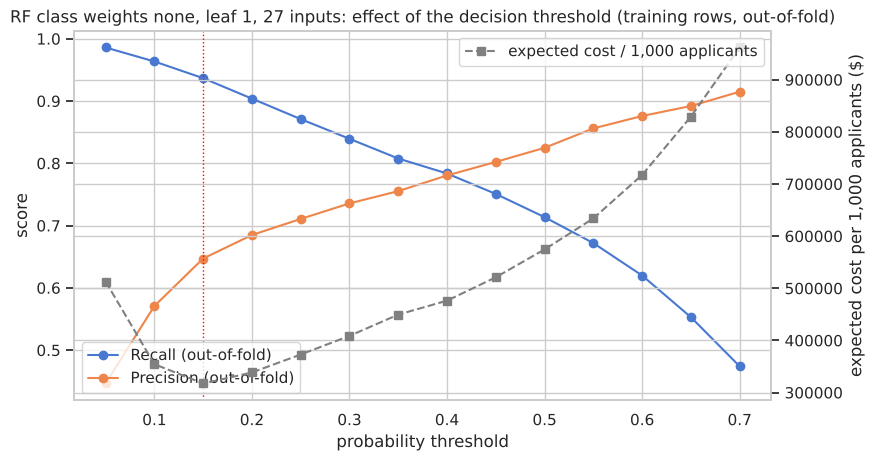

,threshold,recall,precision,accuracy,missed_defaulters_per_1000,good_customers_declined_per_1000,expected_cost_per_1000_$
0,0.050000,0.986,0.446,0.753,2.8,243.8,"512,864"
1,0.100000,0.964,0.571,0.848,7.3,144.5,"354,346"
2,0.150000,0.937,0.647,0.886,12.6,101.9,"317,354"
3,0.200000,0.904,0.685,0.898,19.2,82.9,"338,447"
4,0.250000,0.871,0.711,0.904,25.7,70.7,"372,963"
5,0.300000,0.839,0.736,0.908,32.0,60.2,"408,677"
6,0.350000,0.808,0.755,0.909,38.4,52.2,"449,505"
7,0.400000,0.784,0.781,0.913,43.1,43.9,"476,190"
8,0.450000,0.751,0.802,0.913,49.7,36.9,"521,093"
9,0.500000,0.714,0.825,0.913,57.1,30.2,"574,545"


In [70]:
# Out-of-fold cost curve of the winner (mean over the three repeated 5-fold splits)
tbl = oof[winner]["table"]
fig, ax1 = plt.subplots(figsize=(9, 4.8))
ax1.plot(tbl["threshold"], tbl["recall"], marker="o", label="Recall (out-of-fold)")
ax1.plot(tbl["threshold"], tbl["precision"], marker="o", label="Precision (out-of-fold)")
ax1.set_xlabel("probability threshold"); ax1.set_ylabel("score"); ax1.legend(loc="lower left")
ax2 = ax1.twinx()
ax2.plot(tbl["threshold"], tbl["expected_cost_per_1000_$"], color="grey", linestyle="--", marker="s", label="expected cost / 1,000 applicants")
ax2.set_ylabel("expected cost per 1,000 applicants ($)"); ax2.legend(loc="upper right")
ax1.axvline(FINAL_THRESHOLD, color="red", linestyle=":", linewidth=1)
plt.title(f"{winner}: effect of the decision threshold (training rows, out-of-fold)")
plt.show()

tbl.style.format({"recall": "{:.3f}", "precision": "{:.3f}", "accuracy": "{:.3f}", "missed_defaulters_per_1000": "{:.1f}",
                  "good_customers_declined_per_1000": "{:.1f}", "expected_cost_per_1000_$": "{:,.0f}"}).highlight_min(subset=["expected_cost_per_1000_$"], color="#c6efce")

In [71]:
# How sensitive is the chosen threshold to the cost assumptions? Re-run the threshold choice for other cost ratios.
rows = []
for ratio in [2, 3, 4.5, 6, 9]:
    costs = []
    for t in THRESHOLDS:
        c = 0
        for proba_oof in oof[winner]["probas"]:
            tn, fp, fn, tp = confusion_matrix(y_train, (proba_oof > t).astype(int)).ravel()
            c += fn * ratio + fp
        costs.append(c)
    rows.append({"cost of a missed defaulter / cost of a wrongly declined customer": f"{ratio}:1",
                 "cost-minimising threshold": THRESHOLDS[int(np.argmin(costs))],
                 "break-even threshold for a perfectly calibrated score": round(1 / (1 + ratio), 2)})
pd.DataFrame(rows)

,cost of a missed defaulter / cost of a wrongly declined customer,cost-minimising threshold,break-even threshold for a perfectly calibrated score
0,2:1,0.200,0.330
1,3:1,0.150,0.250
2,4.5:1,0.150,0.180
3,6:1,0.150,0.140
4,9:1,0.100,0.100


**Observations - model and threshold selection:**
- On repeated out-of-fold predictions the **unweighted forest on all 27 inputs has the lowest expected cost**, about \$317,000 per 1,000 applicants. The 12-input version costs about a fifth more (\$378,000): occupation, loan purpose and the minor missing flags barely registered at the 0.5 threshold but add up to a measurable gain at the cost-optimal operating point, so the simpler model is not within one standard error and is not chosen. The recall-tuned grid winner is far worse (\$490,000) once precision is priced in, which confirms that recall-only tuning over-shoots.
- The cost-minimising threshold is **0.15**: flag every applicant whose estimated default probability exceeds 15%. It stays at 0.15 for any cost ratio between 3:1 and 6:1; at 2:1 it would move to 0.20 and only if a missed defaulter were nine times as costly as a wrongly declined customer would it drop to 0.10. The choice is robust to the assumptions, and it agrees with the theoretical break-even for a well-calibrated score at the stated costs, \$2,000 / (\$9,000 + \$2,000) = 0.18, which is further evidence that the forest's probabilities are meaningful.
- The mean out-of-fold ROC-AUC of the winner (0.961) matches its test ROC-AUC below, so the training-based selection is not optimistic.

In [72]:
# The final solution written out end to end, so that every step and every input to the scoring model is explicit
flag_cols = [c for c in final_cols if c.endswith("_missing")]
dummy_cols = [c for c in final_cols if c.startswith(("REASON_", "JOB_")) and c not in flag_cols]
raw_cols = [c for c in final_cols if c not in flag_cols + dummy_cols]
assert len(final_cols) == len(raw_cols) + len(flag_cols) + len(dummy_cols) == 27
assert final_cols == list(X_train.columns), "the final model uses every prepared column, in this order"

print(f"FINAL PIPELINE  (every statistic below was learned on the {len(train_idx):,} training rows only)")
print(f"1. Raw inputs kept as numbers ({len(raw_cols)}):", raw_cols)
print(f"2. Missing-value flags, 1 if the field was blank ({len(flag_cols)}):", flag_cols)
print("3. Imputation of blanks - training-row medians:", {k: round(v, 2) for k, v in hm.loc[train_idx, num_cols].median().items()})
print("                          training-row modes  :", {c: hm.loc[train_idx, c].mode()[0] for c in ["REASON", "JOB"]})
print(f"4. One-hot encoding of REASON and JOB, first level dropped ({len(dummy_cols)}):", dummy_cols)
print("5. No outlier capping and no scaling: tree ensembles are unaffected by monotone transformations of an input")
print("6. Model:", type(final_model).__name__, {k: v for k, v in final_model.get_params().items()
      if k in ["n_estimators", "class_weight", "min_samples_leaf", "max_features", "max_depth", "random_state"]})
print(f"7. Model inputs, in order ({len(final_cols)}):", final_cols)
print(f"8. Decision rule: flag the applicant when the predicted default probability exceeds {FINAL_THRESHOLD:.2f}")

FINAL PIPELINE  (every statistic below was learned on the 4,172 training rows only)
1. Raw inputs kept as numbers (10): ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
2. Missing-value flags, 1 if the field was blank (11): ['MORTDUE_missing', 'VALUE_missing', 'REASON_missing', 'JOB_missing', 'YOJ_missing', 'DEROG_missing', 'DELINQ_missing', 'CLAGE_missing', 'NINQ_missing', 'CLNO_missing', 'DEBTINC_missing']
3. Imputation of blanks - training-row medians: {'LOAN': 16200.0, 'MORTDUE': 66293.0, 'VALUE': 89965.0, 'YOJ': 7.0, 'DEROG': 0.0, 'DELINQ': 0.0, 'CLAGE': 173.87, 'NINQ': 1.0, 'CLNO': 20.0, 'DEBTINC': 34.84}
                          training-row modes  : {'REASON': 'DebtCon', 'JOB': 'Other'}
4. One-hot encoding of REASON and JOB, first level dropped (6): ['REASON_HomeImp', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']
5. No outlier capping and no scaling: tree ensembles are unaffected by monotone transformations of an i

Final model: RF class weights none, leaf 1, 27 inputs at threshold 0.15 - TEST SET
              precision    recall  f1-score   support

           0      0.980     0.892     0.934      1431
           1      0.681     0.927     0.785       357

    accuracy                          0.899      1788
   macro avg      0.831     0.909     0.860      1788
weighted avg      0.920     0.899     0.904      1788



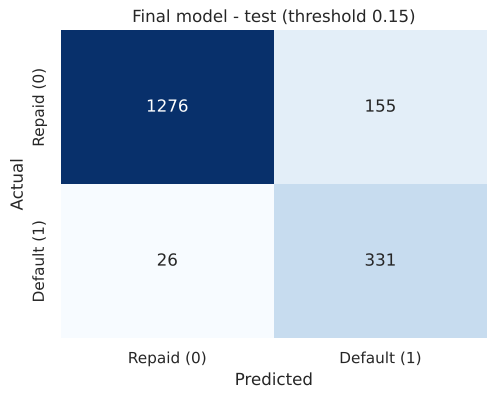

Test ROC-AUC: 0.963


,threshold,recall,precision,accuracy,missed_defaulters_per_1000,good_customers_declined_per_1000,expected_cost_per_1000_$
0,0.150000,0.927,0.681,0.899,14.5,86.7,"304,251"
1,0.500000,0.686,0.842,0.912,62.6,25.7,"615,213"


In [73]:
# Fit the selected model on all training rows and score the test set ONCE, at the selected threshold and at 0.5 for reference
final_model.fit(X_train[final_cols], y_train)
proba_test = final_model.predict_proba(X_test[final_cols])[:, 1]
final_pred = (proba_test > FINAL_THRESHOLD).astype(int)

print(f"Final model: {winner} at threshold {FINAL_THRESHOLD:.2f} - TEST SET")
metrics_score(y_test, final_pred, title=f"Final model - test (threshold {FINAL_THRESHOLD:.2f})")
print(f"Test ROC-AUC: {roc_auc_score(y_test, proba_test):.3f}")

test_tbl = cost_table(y_test, proba_test, thresholds=np.array([FINAL_THRESHOLD, 0.5]))
test_tbl.style.format({"recall": "{:.3f}", "precision": "{:.3f}", "accuracy": "{:.3f}", "missed_defaulters_per_1000": "{:.1f}",
                       "good_customers_declined_per_1000": "{:.1f}", "expected_cost_per_1000_$": "{:,.0f}"})

**Observations - final model on unseen applicants:**
- At the selected 0.15 threshold the forest catches about **93% of defaulters** on the test set with about **68% precision** and 90% accuracy. Per 1,000 applicants that is roughly 185 of 200 defaulters flagged in advance, about 15 missed and about 87 good customers declined or referred.
- At the conventional 0.5 threshold the same forest would catch only about 69% of defaulters (with 84% precision): it would miss about 63 defaulters per 1,000 instead of 15, and decline about 26 good customers instead of 87. Under the stated costs the lower threshold halves the expected cost of credit errors (about \$0.30 million vs \$0.62 million per 1,000 applicants).
- The test numbers are within a few points of the out-of-fold estimates (recall 93% vs 94%, precision 68% vs 65%, cost \$304,000 vs \$317,000 per 1,000), which is the evidence that the selection procedure did not over-fit.

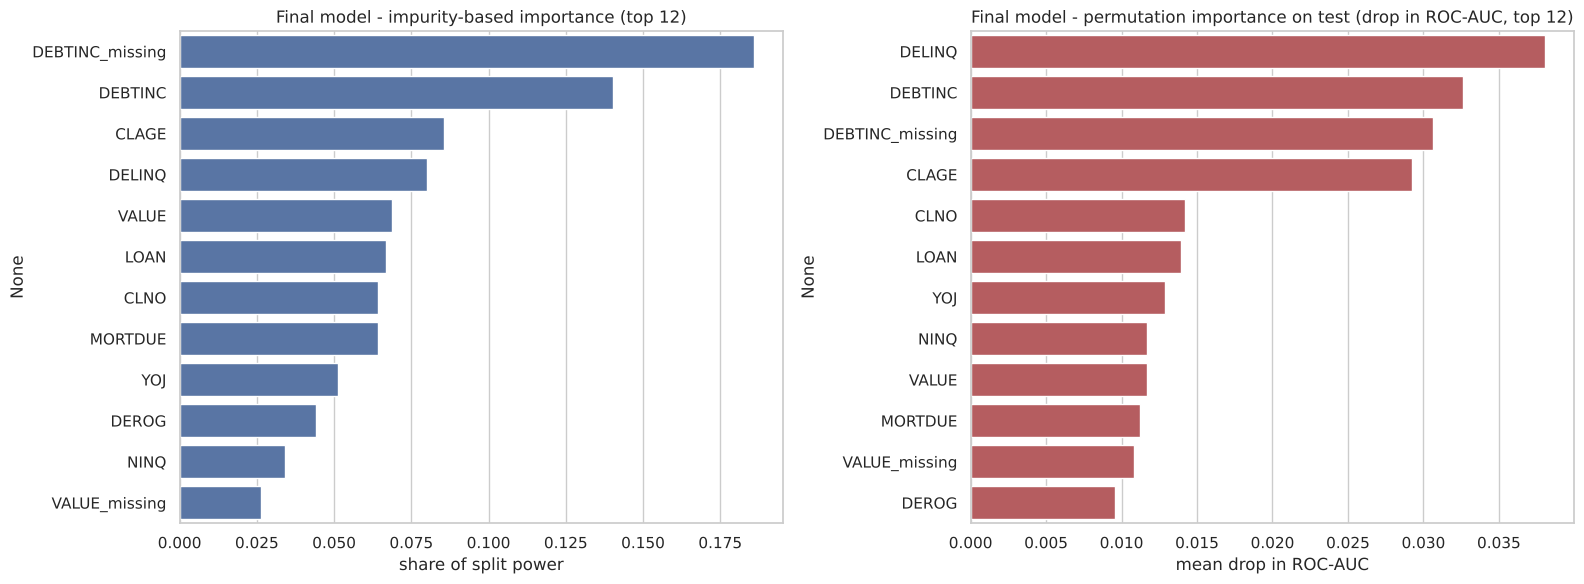

,impurity_importance,permutation_importance_auc_drop
DEBTINC_missing,0.186,0.031
DEBTINC,0.140,0.033
CLAGE,0.086,0.029
DELINQ,0.080,0.038
VALUE,0.069,0.012
LOAN,0.067,0.014
CLNO,0.064,0.014
MORTDUE,0.064,0.011
YOJ,0.051,0.013
DEROG,0.044,0.010


In [74]:
# What the final model relies on: impurity-based importance of the fitted forest, and permutation importance
# (drop in test ROC-AUC when a column is shuffled), which does not favour variables with many split points.
mdi = pd.Series(final_model.feature_importances_, index=final_cols).sort_values(ascending=False)
perm = permutation_importance(final_model, X_test[final_cols], y_test, scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=final_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=mdi.values[:12], y=mdi.index[:12], color="#4C72B0", ax=axes[0])
axes[0].set_title("Final model - impurity-based importance (top 12)"); axes[0].set_xlabel("share of split power")
sns.barplot(x=perm_imp.values[:12], y=perm_imp.index[:12], color="#C44E52", ax=axes[1])
axes[1].set_title("Final model - permutation importance on test (drop in ROC-AUC, top 12)"); axes[1].set_xlabel("mean drop in ROC-AUC")
plt.tight_layout(); plt.show()

pd.DataFrame({"impurity_importance": mdi.round(3), "permutation_importance_auc_drop": perm_imp.round(4)}).sort_values("impurity_importance", ascending=False).head(12)

**Insights - what the final model relies on:**
- Both views agree on the core drivers: the **debt-to-income ratio and its missing flag, the number of delinquent credit lines and the age of the credit history**. Together they carry about half of the forest's split power (0.49) and produce the four largest drops in ranking quality when shuffled.
- Impurity importance spreads the remaining weight over the property value, loan and mortgage amounts, the number of credit lines and job tenure (continuous variables with many split points); permutation importance ranks `DELINQ` first, i.e. repayment behaviour, and gives the amounts less weight. Occupation, loan purpose and the minor missing flags each matter little on their own but, as the selection table showed, add up to a measurable gain at the cost-optimal threshold.

#### An explanation layer that follows the forest: a surrogate decision tree

The ECOA requires a specific reason for each adverse decision. A forest of 200 trees cannot be read directly, so a **surrogate decision tree is fitted to the forest's own decisions** (its flag / do-not-flag outcome at the 0.15 threshold on the training rows, not to the original labels). Its agreement with the forest on the test applicants, its *fidelity*, measures how faithfully the rules describe what the scoring engine actually does.

In [75]:
forest_decision_train = (final_model.predict_proba(X_train[final_cols])[:, 1] > FINAL_THRESHOLD).astype(int)
forest_decision_test = final_pred

fidelity = {}
for depth in [3, 4, 5]:
    sur = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=RANDOM_STATE)
    sur.fit(X_train[final_cols], forest_decision_train)
    fidelity[depth] = (sur.predict(X_test[final_cols]) == forest_decision_test).mean()
print("Agreement of the surrogate tree with the forest's test decisions, by depth:",
      {d: f"{f:.1%}" for d, f in fidelity.items()})

surrogate = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=RANDOM_STATE)
surrogate.fit(X_train[final_cols], forest_decision_train)
print(f"\nSurrogate tree (depth 4) reproduces {fidelity[4]:.1%} of the forest's decisions on unseen applicants.\n")
print(export_text(surrogate, feature_names=final_cols, max_depth=4, show_weights=False))

Agreement of the surrogate tree with the forest's test decisions, by depth: {3: '89.4%', 4: '90.3%', 5: '90.4%'}

Surrogate tree (depth 4) reproduces 90.3% of the forest's decisions on unseen applicants.

|--- DEBTINC_missing <= 0.50
|   |--- DEBTINC <= 45.15
|   |   |--- DELINQ <= 1.50
|   |   |   |--- DEBTINC <= 43.71
|   |   |   |   |--- class: 0
|   |   |   |--- DEBTINC >  43.71
|   |   |   |   |--- class: 0
|   |   |--- DELINQ >  1.50
|   |   |   |--- MORTDUE <= 45523.00
|   |   |   |   |--- class: 1
|   |   |   |--- MORTDUE >  45523.00
|   |   |   |   |--- class: 0
|   |--- DEBTINC >  45.15
|   |   |--- CLAGE <= 157.39
|   |   |   |--- class: 1
|   |   |--- CLAGE >  157.39
|   |   |   |--- class: 1
|--- DEBTINC_missing >  0.50
|   |--- DELINQ <= 0.50
|   |   |--- CLAGE <= 178.43
|   |   |   |--- DEROG_missing <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- DEROG_missing >  0.50
|   |   |   |   |--- class: 1
|   |   |--- CLAGE >  178.43
|   |   |   |--- DEROG <= 0.50
|   | 

**Insights - the surrogate tree:**
- A four-level tree reproduces about **90% of the forest's decisions** on unseen applicants (89% at depth 3, 90% at depth 5, so depth 4 is the useful compromise), so its rules are a faithful summary of the scoring engine, not a separate model with its own opinions.
- The rules are the same drivers the EDA and the stand-alone tree found: *Is the debt-to-income ratio missing? If recorded, is it above about 45%? Are there two or more delinquent credit lines? How long is the credit history, and are there derogatory reports?* An applicant whose ratio is missing is flagged unless they have no delinquent lines, no derogatory reports and a credit history of more than about 15 years; an applicant with a recorded ratio above 45% is flagged whatever their history; one with a ratio at or below 45% is flagged only with two or more delinquent lines (and, in the surrogate, a mortgage balance below about \$45,500). An applicant who is flagged can therefore be told which of these conditions applied to them.
- For the roughly 10% of decisions the surrogate does not reproduce, and for a per-applicant explanation in all cases, the production system should also report the applicant's top risk drivers from the forest itself (for example with SHAP-style reason codes, listed under further analysis).

In [76]:
# Indicative business impact per 1,000 applicants (test set): current process vs each technique at 0.5, and the final model
def impact_per_1000(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    n = len(y_true)
    return {"defaulters_caught_per_1000": round(1000 * tp / n, 1),
            "defaulters_missed_per_1000": round(1000 * fn / n, 1),
            "good_customers_declined_per_1000": round(1000 * fp / n, 1),
            "expected_cost_per_1000_$": round(1000 * (fn * COST_FN + fp * COST_FP) / n)}

baseline_cost = round(1000 * y_test.mean() * COST_FN)   # today's outcome on these (approved) applicants: every defaulter is missed
impact = pd.DataFrame({
    "Current process (all of these applicants were approved)": {"defaulters_caught_per_1000": 0.0,
                                      "defaulters_missed_per_1000": round(1000 * y_test.mean(), 1),
                                      "good_customers_declined_per_1000": 0.0,
                                      "expected_cost_per_1000_$": baseline_cost},
    "Logistic Regression (balanced), threshold 0.5": impact_per_1000(y_test_lr, lr_bal.predict(X_test_lr_s)),
    "Decision Tree (tuned), threshold 0.5": impact_per_1000(y_test, dt_tuned.predict(X_test)),
    "Random Forest (class weights), threshold 0.5": impact_per_1000(y_test, rf_cw.predict(X_test)),
    f"Final model, threshold {FINAL_THRESHOLD:.2f}": impact_per_1000(y_test, final_pred),
}).T
impact["cost_reduction_vs_current_%"] = ((1 - impact["expected_cost_per_1000_$"] / baseline_cost) * 100).round(1)
impact

,defaulters_caught_per_1000,defaulters_missed_per_1000,good_customers_declined_per_1000,expected_cost_per_1000_$,cost_reduction_vs_current_%
Current process (all of these applicants were approved),0.000,199.700,0.000,"1,796,980.000",0.000
"Logistic Regression (balanced), threshold 0.5",158.800,40.800,102.300,"572,148.000",68.200
"Decision Tree (tuned), threshold 0.5",163.900,35.800,144.900,"611,857.000",66.000
"Random Forest (class weights), threshold 0.5",154.400,45.300,46.400,"500,559.000",72.100
"Final model, threshold 0.15",185.100,14.500,86.700,"304,251.000",83.100


**Observations - indicative benefit:**
- Against today's outcome on these applicants (all approved, 20% defaulted), every model removes most of the default-related cost. At the 0.5 threshold the class-weighted forest cuts the indicative expected cost per 1,000 applicants by roughly 72%, the logistic regression by about 68% and the tuned tree by about 66%, mainly because the tree and the linear model decline many more good customers (about 102 and 145 per 1,000 against 46 for the forest).
- At its selected threshold the final model cuts the cost by about 83%: about 185 of 200 defaulters caught and about 87 good customers declined per 1,000.
- These figures use round-number assumptions and the test applicants, who were all approved by the old process; the bank's finance team should replace the assumptions with actual loss-given-default and margin figures, and the shadow period will show how the model behaves on the applicants the old process declined.

**2. Refined insights:**
- What are the most meaningful insights relevant to the problem?

1. **Affordability, and whether it can be verified, decides most outcomes.** The debt-to-income ratio and its missing-flag are the top features in every model. An applicant with no verifiable ratio defaulted 62% of the time; one with a ratio above 45% defaulted 87% to 100% of the time. These two checks alone would have caught a large share of historical defaults.

2. **Past repayment behaviour is the next strongest predictor.** Delinquent credit lines, major derogatory reports and recent credit inquiries all raise default risk as they increase. The decision tree's top splits, the forest's importances and the permutation test agree on this.

3. **Credit history length protects.** Applicants with 20+ years of credit history default about 10% of the time versus 44% for those with under 5 years.

4. **Loan size, property value and mortgage balance are secondary.** Their differences between defaulters and repayers are statistically significant but small; they matter in combination (small loans are riskier, missing valuations are almost always bad) rather than on their own. The 0.88 correlation between `VALUE` and `MORTDUE` means they largely carry the same information.

5. **Occupation and loan purpose matter little on their own but are not worthless.** They barely move performance at the 0.5 threshold, yet dropping them (and nine minor missing flags) raised the out-of-fold expected cost of the final model by about a fifth. Their use should be cleared by the fair-lending review; the 12-input model is the fallback.

6. **The models agree with each other and with the EDA.** The linear coefficients, the tree's rules, the forest's importances and the surrogate tree all point to the same handful of drivers, which gives confidence that the signal is real and stable.

7. **Handling the imbalance and the missingness mattered more than the choice of algorithm.** At the 0.5 cut-off, class weights improved recall by about 23 points for the logistic regression and 9 for the forest, and averaging trees (bagging) mainly bought precision and ranking quality. Once the decision threshold was chosen on cost, however, the class weights were no longer needed: the unweighted forest with a 0.15 cut-off was the cheapest configuration, and the weighted forests were within noise of it at their own cut-offs.

8. **The decision threshold is a business dial, and it should be set on training data.** With the forest's strong ranking ability (ROC-AUC 0.96) the bank can move recall between about 70% and 94% by changing the cut-off. The cost-minimising cut-off of 0.15, chosen on repeated out-of-fold predictions, catches about 93% of defaulters with 68% precision on unseen applicants, is robust to the cost assumptions and agrees with the theoretical break-even (0.18) for the stated costs.

**3. Proposal for the final solution design:**
- What model do you propose to be adopted? Why is this the best solution to adopt?

### Proposed solution: a Random Forest scoring engine with a cost-based decision threshold, explained by a surrogate decision tree

**Model specification**
- `RandomForestClassifier` with 200 fully grown trees and **no class weights** (the configuration search showed that, once the threshold is chosen on cost, class weights add nothing), trained on the untreated data with the 27 model inputs listed in the final-pipeline cell: the ten financial attributes, the eleven missing-value flags and the six occupation and loan-purpose indicators. Pre-processing: a missing flag per column plus median/mode imputation learned on the training rows; no outlier capping, no scaling.
- **Decision threshold 0.15**, chosen by minimising the indicative expected cost on repeated out-of-fold predictions of the training rows, instead of the default 0.5; to be re-derived with the bank's own loss-given-default and margin figures (the choice was stable for cost ratios between 3:1 and 6:1 and agrees with the theoretical break-even of 0.18 for the stated costs).
- **Explanation layer:** a depth-4 surrogate decision tree fitted to the forest's decisions, which reproduces about 90% of them on unseen applicants, plus per-applicant top risk drivers for the adverse-action notice.
- **Fallback:** the same forest on 12 inputs (no occupation or loan purpose, only the debt-to-income and property-value missing flags) if the fair-lending review requires it; it costs about a fifth more in expected credit errors.

**Why this is the best solution to adopt**
1. **Lowest expected cost of credit errors, chosen without looking at the test set.** Among ten forest configurations and four final candidates it had the lowest repeated out-of-fold expected cost at its best threshold, and on the held-out applicants it then delivered about 93% recall at 68% precision and 90% accuracy, with a ROC-AUC of about 0.96. The single decision tree (82% recall at 53% precision) and the logistic regression (80% at 61%) are far behind on precision, and the recall-tuned forest buys its recall with too much precision.
2. **Robust.** Averaging hundreds of trees removes the instability of a single tree; the out-of-fold and test results agree, and the threshold is insensitive to the cost assumptions over a wide range.
3. **Interpretable enough for ECOA.** The surrogate tree gives a short, faithful rule list (debt-to-income missing or above about 45%, delinquent lines, credit-history length, derogatory reports); global importances and per-applicant reason codes document the score itself. Because the forest is unweighted, its score is an estimated default rate and the 0.15 cut-off reads directly as the bank's risk appetite.
4. **Operationally simple.** The inputs are all fields already captured in the underwriting process; no new data is required to deploy, and the first process change the analysis recommends (mandatory income and valuation verification) improves the data for every future model.

**Why not the alternatives**
- *Logistic regression (balanced):* fully transparent, but at a similar recall it mis-classifies many more good customers (precision 61% vs 77% at the 0.5 threshold) because it cannot represent the threshold effects on the raw inputs.
- *Tuned decision tree:* highest recall at 0.5 (82%) but precision of 53% means too much lost business; it is better used as a rule summary than as the scorer.
- *Bagged trees:* a clear improvement over a single tree (precision 83%, ROC-AUC 0.95) but it misses a third of defaulters and class weights do not move its recall; the forest dominates it on every metric that matters.
- *Class-weighted random forests (0.2/0.8 or balanced):* the best balance at the 0.5 cut-off, and within one standard error of the final model once their own thresholds are tuned (0.25); the unweighted forest was preferred under the pre-stated rule as the simplest configuration with the lowest mean cost.
- *Recall-tuned random forest:* the cross-validated grid winner on recall, but its constrained trees (at least 10 applicants per leaf) give cruder probabilities, and once precision is priced in its expected cost is about half again as high as the final forest's.
- *The forest at the default 0.5 cut-off:* best precision (84%) but misses almost a third of defaulters, which is the costlier error; moving the cut-off to 0.15 is what turns it into the final model.

**Guard-rails for adoption**
- Run the model in shadow mode on all applications (including those the old process would decline, which the training data does not cover) for one to two months before switching it on.
- Monitor recall, precision and the approval rate monthly; re-train at least yearly or when the default rate drifts, and re-derive the threshold whenever the cost assumptions change.
- Run a fairness review on the final model (approval rates and error rates across protected groups) before launch; keep the 12-input fallback ready if occupation has to be excluded.
- Keep a human underwriter in the loop for applicants in the uncertain band around the threshold (predicted probability between roughly 0.10 and 0.25) during the first months.

---
### Summary of answers to the leading questions

| # | Question | Answer |
|---|---|---|
| 1 | Range of LOAN | \$1,100 to \$89,900; median \$16,300; right-skewed |
| 2 | Distribution of YOJ | Right-skewed; most applicants 0-5 years, median 7, tail to 41 |
| 3 | Unique categories in REASON | 2 (DebtCon 69%, HomeImp 31%) |
| 4 | Most common JOB | "Other" (42%), then ProfExe (22%) and Office (17%) |
| 5 | REASON vs default | Weak but statistically significant relationship: HomeImp 22.2% vs DebtCon 19.0% (chi-square p = 0.005) |
| 6 | LOAN for defaulters vs repayers | Defaulters borrow less (median \$14,900 vs \$16,900; Mann-Whitney p < 0.001); loans under \$5,000 default 57% of the time |
| 7 | VALUE vs default | Very weak correlation (-0.03); but a *missing* valuation defaults 94% of the time |
| 8 | MORTDUE for defaulters vs repayers | Lower for defaulters (median \$60,279 vs \$66,839; Mann-Whitney p < 0.001) but a small difference in practice |